# S18 · RL sin modelo: Gymnasium y Q-Learning

En la S17 resolvimos FrozenLake **conociendo** $P(s'|s,a)$ y $R(s,a)$. Hoy el agente no los conoce: solo puede jugar.

1. Gymnasium: el contrato `reset` / `step`
2. Agente aleatorio (la línea base)
3. De Bellman a Q-Learning: cambiar la esperanza por muestras
4. Q-Learning tabular en FrozenLake y comparación con $Q^\star$ de la S17
5. El bug de `terminated`
6. SARSA: un símbolo de diferencia
7. Efecto de $\alpha$ y $\gamma$
8. Un entorno de trading mínimo y cómo validarlo
9. Por qué la tabla no escala a trading

In [1]:
import sys; sys.path.append("src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from frozenlake_utils import *

SEED = 42
np.set_printoptions(precision=3, suppress=True)

## 1. Gymnasium: el contrato estándar

Todo entorno expone lo mismo, sin importar si es un juego o un mercado:

| método | devuelve |
|---|---|
| `env.reset(seed)` | `obs, info` |
| `env.step(a)` | `obs, reward, terminated, truncated, info` |

- `terminated`: terminó por la **tarea** (hoyo, meta, quiebra). El futuro vale 0: **no** se hace bootstrap.
- `truncated`: terminó por **tiempo** (límite de pasos, fin de datos). El futuro existe: **sí** se hace bootstrap.

In [2]:
env = gym.make("FrozenLake-v1", is_slippery=True)
nS, nA = env.observation_space.n, env.action_space.n

print("observation_space:", env.observation_space, "  action_space:", env.action_space)
print("límite de pasos por episodio:", env.spec.max_episode_steps)

obs, info = env.reset(seed=SEED)
print("\nobs inicial:", obs, " info:", info)

a = 2                                                   # Derecha
obs, r, terminated, truncated, info = env.step(a)
print(f"step({a}) -> obs={obs}, r={r}, terminated={terminated}, truncated={truncated}, info={info}")

observation_space: Discrete(16)   action_space: Discrete(4)
límite de pasos por episodio: 100

obs inicial: 0  info: {'prob': 1}
step(2) -> obs=1, r=0, terminated=False, truncated=False, info={'prob': 0.3333333333333333}


**Observa:** pedimos Derecha y no necesariamente acabamos en la celda 1: el hielo resbala.
`info["prob"]` es la probabilidad de esa transición; el agente **no** debe usarla (sería espiar el modelo).

**Mi explicación (sección 1).**
El entorno tiene 16 estados (las celdas del tablero de 4x4) y 4 acciones, y Gymnasium le pone un límite de 100 pasos por episodio; ese límite es lo que más adelante genera `truncated=True`.
Desde la celda 0 pedí Derecha y llegué a la celda 1, pero `info["prob"]=1/3` dice que fue suerte: con `is_slippery=True` el agente se mueve en la dirección pedida o en alguna de las dos perpendiculares, cada una con probabilidad 1/3.
La recompensa es 0 y las dos banderas son `False` porque no se llegó ni a un hoyo ni a la meta ni al límite de pasos. Lo importante es que la interfaz es siempre la misma: `reset` devuelve `(obs, info)` y `step` devuelve cinco valores.

## 2. Agente aleatorio: la línea base

Antes de entrenar nada, medimos qué tan bien le va a quien elige al azar (`action_space.sample()`).
Contamos también **cómo** termina cada episodio.

In [3]:
def correr_aleatorio(env, n_episodios=2000, semilla=SEED):
    # Agente aleatorio: devuelve recompensas por episodio y cuántos terminaron vs. truncaron.
    env.action_space.seed(semilla)
    env.reset(seed=semilla)
    retornos, fin = [], {"terminated": 0, "truncated": 0}
    for _ in range(n_episodios):
        obs, _ = env.reset()
        total, terminado, truncado = 0.0, False, False
        while not (terminado or truncado):
            obs, r, terminado, truncado, _ = env.step(env.action_space.sample())
            total += r
        fin["terminated" if terminado else "truncated"] += 1
        retornos.append(total)
    return np.array(retornos), fin

ret_azar, fin = correr_aleatorio(env)
print(f"FrozenLake · aleatorio: éxito {ret_azar.mean():.1%}   fines: {fin}")

env_cp = gym.make("CartPole-v1")
ret_cp, fin_cp = correr_aleatorio(env_cp, n_episodios=500)
print(f"CartPole   · aleatorio: retorno medio {ret_cp.mean():.1f} (min {ret_cp.min():.0f}, max {ret_cp.max():.0f}) de 500 posibles   fines: {fin_cp}")

FrozenLake · aleatorio: éxito 1.8%   fines: {'terminated': 2000, 'truncated': 0}


CartPole   · aleatorio: retorno medio 21.6 (min 8, max 73) de 500 posibles   fines: {'terminated': 500, 'truncated': 0}


El mismo código corre en dos entornos distintos: esa es la ventaja de un contrato estándar.
En CartPole todo termina por `terminated` (el palo cae); en FrozenLake casi todo es caer en un hoyo.

**Mi explicación (sección 2).**
El agente aleatorio llega a la meta solo en 1.8% de los 2000 episodios (36 episodios), y los 2000 acabaron por `terminated`: casi siempre cae a un hoyo mucho antes de llegar a los 100 pasos, por eso no hay ningún `truncated`.
En CartPole el promedio es 21.6 pasos de 500 posibles (entre 8 y 73) y también todo termina por `terminated`, porque el palo se cae.
Estos números son el piso: cualquier agente que entrenemos tiene que superarlos claramente, y la misma función `correr_aleatorio` funcionó en los dos entornos sin cambiar nada gracias al contrato común.

## 3. De Bellman a Q-Learning

Value iteration (S17) necesitaba el modelo:

$$Q(s,a) \leftarrow \underbrace{\sum_{s'}P(s'|s,a)}_{\text{desconocido}}\Big[r + \gamma\max_{a'}Q(s',a')\Big]$$

**Idea:** no podemos calcular la esperanza, pero sí **observar** una transición $(s,a,r,s')$ y movernos un poco hacia ella.
Eso es Q-Learning (Watkins y Dayan, 1992):

$$Q(s,a) \leftarrow Q(s,a) + \alpha\Big[\underbrace{r + \gamma\max_{a'}Q(s',a')}_{\text{TD target}} - Q(s,a)\Big]$$

El corchete es el **error TD** $\delta$. Para explorar usamos $\varepsilon$-greedy: con prob. $\varepsilon$ una acción al azar, si no $\arg\max_a Q(s,a)$.

In [4]:
def q_learning(env, episodios=20_000, alpha=0.1, gamma=0.99,
               eps=1.0, eps_min=0.05, decay=0.9997, metodo="q",
               bug_terminal=False, Q0=0.0, semilla=SEED):
    # Q-Learning (Watkins y Dayan, 1992) y SARSA (Rummery y Niranjan, 1994) tabulares.
    #   Q-Learning: target = r + γ·max_a' Q(s',a')
    #   SARSA:      target = r + γ·Q(s',a'),  a' = la acción que realmente se tomará
    #   Si terminated: target = r   (bug_terminal=True ignora esta regla, a propósito)
    rng = np.random.default_rng(semilla)
    Q = np.full((nS, nA), Q0, dtype=float)
    elegir = lambda s: int(rng.integers(nA)) if rng.random() < eps else int(Q[s].argmax())
    retornos = []
    env.reset(seed=semilla)
    for ep in range(episodios):
        s, _ = env.reset()
        a = elegir(s)
        terminado = truncado = False
        while not (terminado or truncado):
            s2, r, terminado, truncado, _ = env.step(a)
            a2 = elegir(s2)
            futuro = Q[s2].max() if metodo == "q" else Q[s2, a2]
            if terminado and not bug_terminal:
                futuro = 0.0                                # sin bootstrap al terminar
            Q[s, a] += alpha * (r + gamma * futuro - Q[s, a])
            s, a = s2, a2
        retornos.append(r)                                  # en FrozenLake el retorno es la última r
        eps = max(eps_min, eps * decay)
    return Q, np.array(retornos)

**Mi explicación (sección 3).**
Esta celda no imprime nada, solo define el algoritmo. La línea clave es `futuro`: Q-Learning usa `Q[s2].max()` y SARSA usa `Q[s2, a2]`, donde `a2` es la acción que de verdad se va a tomar. Si el episodio terminó (`terminated`), el futuro se pone en 0; si solo se truncó, se sigue haciendo bootstrap, que es lo correcto.
La exploración empieza con $\varepsilon=1$ y se multiplica por 0.9997 en cada episodio hasta un mínimo de 0.05; eso se alcanza después de $\ln(0.05)/\ln(0.9997)\approx 9{,}985$ episodios, dato que sirve para leer la curva de la sección 4.
Guardar solo la última `r` como retorno es válido aquí porque FrozenLake solo da recompensa (1) al llegar a la meta.

## 4. Q-Learning en FrozenLake

Entrenamos y, como referencia, calculamos $Q^\star$ con value iteration (lo de la S17). El agente **nunca** ve `P` ni `R`.

In [5]:
gamma = 0.99
P, R = construir_modelo(env)                    # solo para comparar, el agente no lo usa
V = np.zeros(nS)
for _ in range(1500):
    Q_star = R + gamma * np.einsum("sap,p->sa", P, V)
    V = Q_star.max(axis=1)
pi_star = Q_star.argmax(axis=1)

Q_ql, ret_ql = q_learning(env, gamma=gamma)
pi_ql = Q_ql.argmax(axis=1)

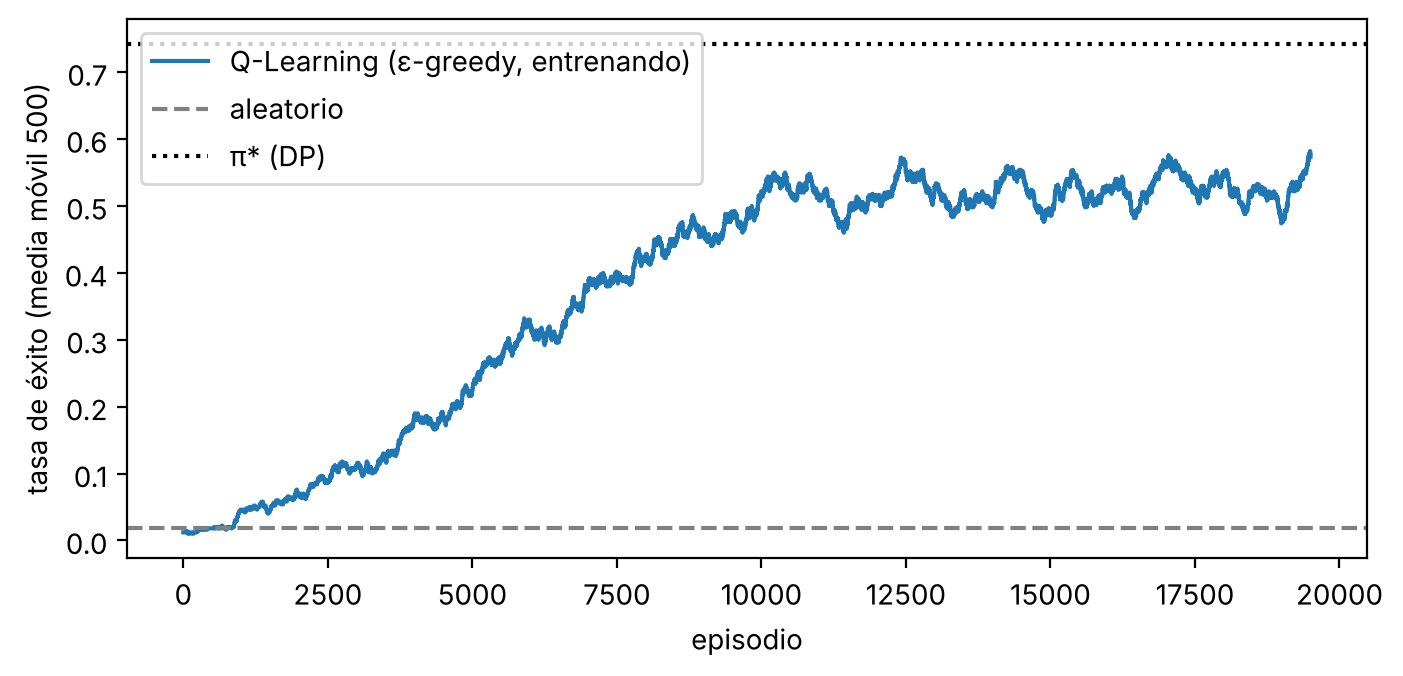

In [6]:
w = 500
media = lambda x: np.convolve(x, np.ones(w) / w, mode="valid")
plt.figure(figsize=(8, 3.5))
plt.plot(media(ret_ql), label="Q-Learning (ε-greedy, entrenando)")
plt.axhline(ret_azar.mean(), color="gray", ls="--", label="aleatorio")
plt.axhline(simular_politica(env, pi_star, semilla=SEED), color="k", ls=":", label="π* (DP)")
plt.xlabel("episodio"); plt.ylabel(f"tasa de éxito (media móvil {w})"); plt.legend(); plt.show()

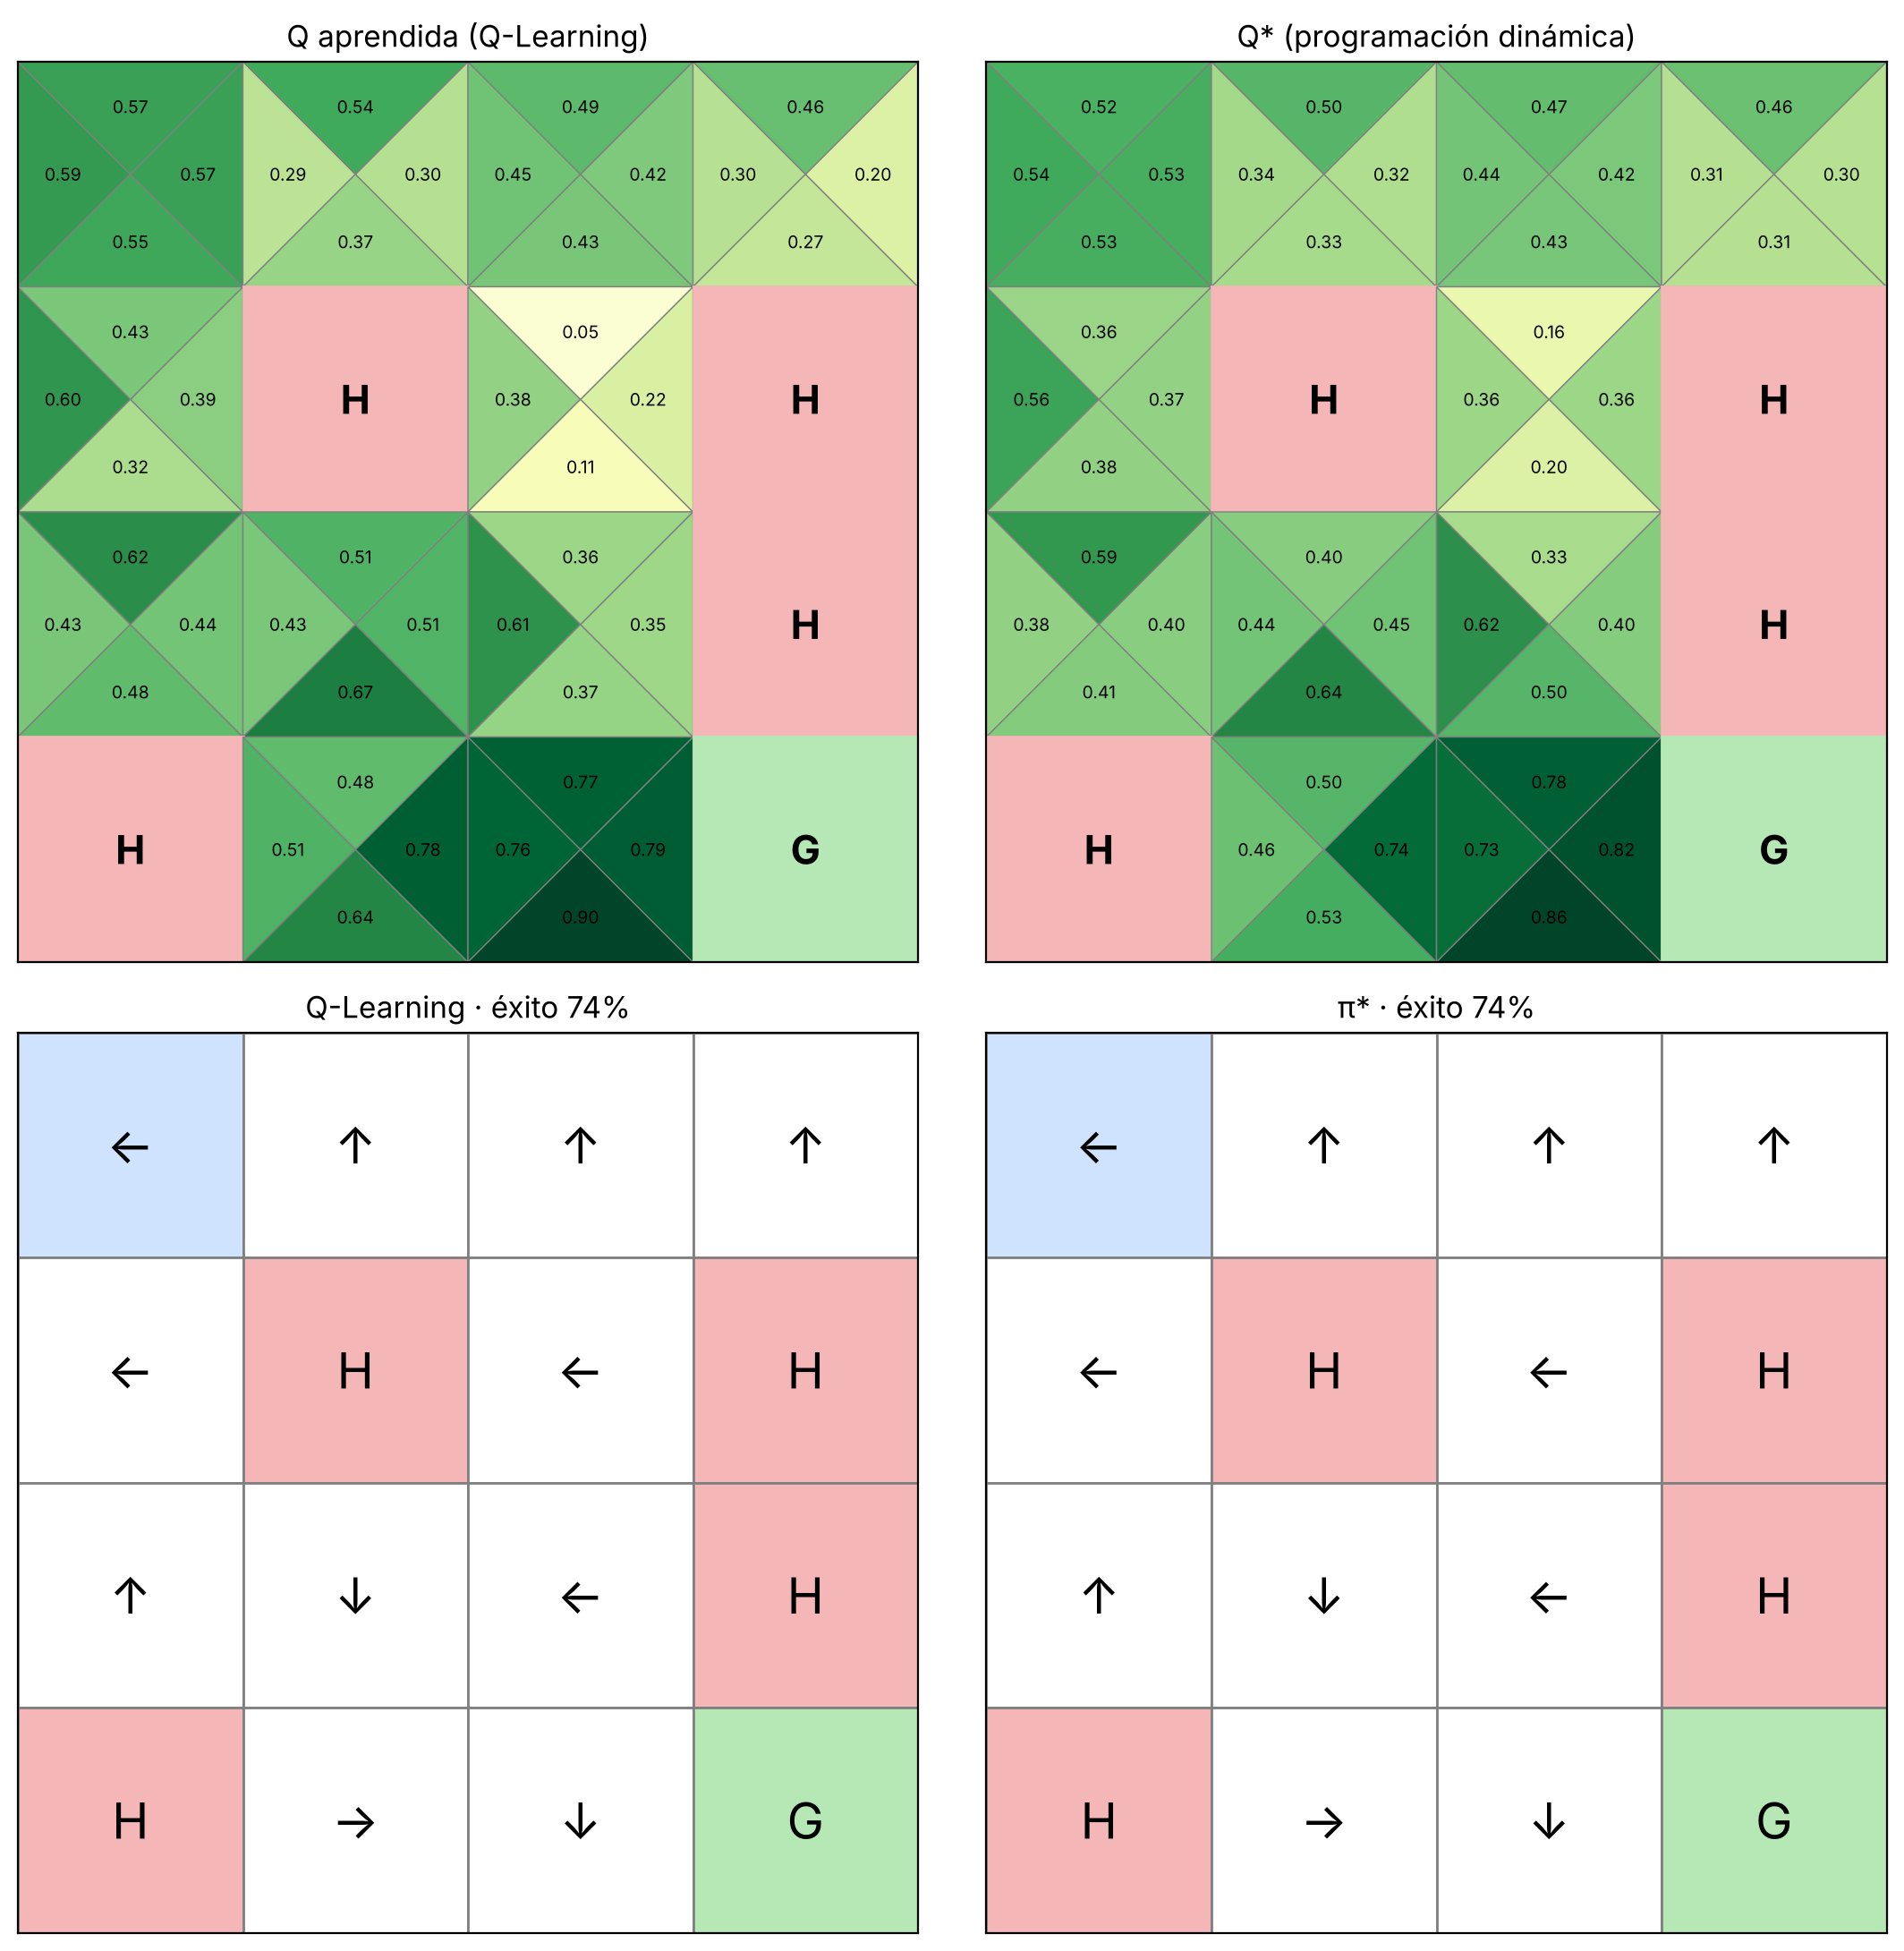

In [7]:
vmax = Q_star[[s for s in range(nS) if s not in estados_terminales(env)]].max()
fig, ax = plt.subplots(2, 2, figsize=(11, 11))
graficar_Q(Q_ql, env, "Q aprendida (Q-Learning)", ax[0, 0], vmax)
graficar_Q(Q_star, env, "Q* (programación dinámica)", ax[0, 1], vmax)
graficar_politica(pi_ql, env, f"Q-Learning · éxito {simular_politica(env, pi_ql, semilla=SEED):.0%}", ax[1, 0])
graficar_politica(pi_star, env, f"π* · éxito {simular_politica(env, pi_star, semilla=SEED):.0%}", ax[1, 1])
plt.tight_layout(); plt.show()

**Lectura:**
- La curva de entrenamiento queda **debajo** de la política final: mientras entrena, el agente sigue explorando con $\varepsilon$.
- Las diferencias con $Q^\star$ están en celdas poco visitadas. Q-Learning converge a $Q^\star$ solo si visita cada $(s,a)$ infinitas veces.
- Q-Learning es **off-policy**: se comporta con $\varepsilon$-greedy pero aprende el valor de la política greedy (el `max`).

**Mi explicación (sección 4).**
La curva de entrenamiento arranca en el nivel del agente aleatorio (alrededor de 2%), sube hasta el episodio 10,000 aproximadamente y luego se estabiliza entre 0.50 y 0.57. Ese punto coincide con el momento en que $\varepsilon$ llega a 0.05 (episodio 9,985, ver sección 3).
Se queda debajo de $\pi^\star$ (74%) porque mientras entrena sigue tomando acciones al azar y un episodio dura unos 44 pasos, así que en cada episodio hay varias acciones aleatorias que pueden mandarlo al hoyo.
La política greedy aprendida es idéntica a la de programación dinámica (mismas flechas, 74% de éxito) aunque los valores no coinciden: Q(6,↑) vale 0.05 contra 0.16 en $Q^\star$ (acción mala, casi no se visita) y Q(14,↓) vale 0.90 contra 0.86, es decir, algunas acciones quedan sobreestimadas (lo retomo en la pregunta 4).
La flecha ← en la salida parece rara, pero aprovecha el resbalón: desde la celda 0 ninguna de las tres direcciones posibles lleva a un hoyo.

## 5. El bug de `terminated`

Si olvidamos quitar el bootstrap al terminar, el valor de los hoyos y la meta se "filtra" hacia atrás.
Con $Q_0=0$ no se nota (las celdas terminales nunca se actualizan y quedan en 0). Con $Q_0=1$ (inicialización optimista) aparece:

In [8]:
Q_ok,  _ = q_learning(env, Q0=1.0)
Q_bug, _ = q_learning(env, Q0=1.0, bug_terminal=True)
no_term = [s for s in range(nS) if s not in estados_terminales(env)]

# El retorno máximo posible en FrozenLake es 1: ningún Q debería pasar de 1
print(f"{'':10s}  max Q(s,a)   Q(6,←)   éxito greedy")
print(f"{'Q*':10s}  {Q_star[no_term].max():10.3f}   {Q_star[6, 0]:6.3f}")
for nombre, Q in [("correcto", Q_ok), ("con bug", Q_bug)]:
    print(f"{nombre:10s}  {Q[no_term].max():10.3f}   {Q[6, 0]:6.3f}   {simular_politica(env, Q.argmax(1), semilla=SEED):11.0%}")

            max Q(s,a)   Q(6,←)   éxito greedy
Q*               0.863    0.358


correcto         0.865    0.120           75%


con bug          1.768    1.084           75%


En la celda 6, ← cae al hoyo 5 con prob. 1/3. Con el bug, el agente toma $Q(\text{hoyo})=1$ como futuro: cree que caer vale $\gamma\cdot 1$ y aparecen valores **mayores a 1**, imposibles.
Aquí la política greedy sale parecida porque el error infla casi todo por igual, pero los valores están corruptos y en otro problema sí cambian el orden de las acciones. Es un bug silencioso: el código corre y "aprende".
En trading, marcar el último bar del histórico como `terminated` enseña que "el mundo se acaba" ahí. El fin de datos es `truncated`.

**Mi explicación (sección 5).**
Con $Q_0=1$ la versión correcta da un máximo de 0.865, prácticamente igual al de $Q^\star$ (0.863). Con el bug el máximo es 1.768 y Q(6,←) vale 1.084, valores imposibles porque el retorno nunca puede pasar de 1.
La razón es que el agente nunca actúa desde un hoyo o desde la meta, así que esas filas de la tabla se quedan en 1 para siempre; si no se corta el bootstrap, cada caída al hoyo se actualiza como si todavía quedara un futuro de valor $\gamma\cdot 1$.
Lo peligroso es que el éxito greedy es 75% en los dos casos: el código corre y la política se ve bien, pero los valores están corruptos. Q(6,←)=0.120 en la versión correcta es menor que 0.358 de $Q^\star$ porque esa acción casi no se explora, no por el bug.

## 6. SARSA: on-policy

$$Q(s,a) \leftarrow Q(s,a) + \alpha\big[r + \gamma\,Q(s',\mathbf{a'}) - Q(s,a)\big]$$

Un solo cambio: $\max_{a'}Q(s',a')$ se reemplaza por $Q(s',a')$ de la acción que **realmente** se toma (incluida la exploración).
SARSA aprende el valor de la política $\varepsilon$-greedy, así que descuenta el costo de sus propios errores: es más cauteloso.

In [9]:
# ε fijo en 0.1 para que la diferencia se vea: ambos exploran igual todo el tiempo
Q_q, r_q = q_learning(env, eps=0.1, eps_min=0.1, metodo="q")
Q_s, r_s = q_learning(env, eps=0.1, eps_min=0.1, metodo="sarsa")

print(f"{'':12s}  éxito entrenando (ε=0.1)   éxito greedy final   V(0) estimado")
for nombre, Q, r in [("Q-Learning", Q_q, r_q), ("SARSA", Q_s, r_s)]:
    print(f"{nombre:12s}  {r[-5000:].mean():22.1%}   {simular_politica(env, Q.argmax(1), semilla=SEED):18.1%}   {Q[0].max():.3f}")
print(f"{'V*(0) de DP':12s}  {'':22s}   {'':18s}   {Q_star[0].max():.3f}")

              éxito entrenando (ε=0.1)   éxito greedy final   V(0) estimado


Q-Learning                     39.6%                74.2%   0.558


SARSA                          37.1%                63.5%   0.277
V*(0) de DP                                                 0.542


SARSA estima un $V(0)$ menor: incluye el riesgo de que, 10% de las veces, haga algo al azar.
**Regla práctica:** si exploras en simulador y solo despliegas la política final, Q-Learning. Si aprendes operando dinero real, la cautela de SARSA vale P&L.

**Mi explicación (sección 6).**
Con $\varepsilon=0.1$ fijo, mientras entrenan los dos tienen un éxito parecido (Q-Learning 39.6%, SARSA 37.1%). La diferencia aparece en lo que aprenden: Q-Learning estima $V(0)=0.558$, cerca de $V^\star(0)=0.542$, y su política greedy logra 74.2%.
SARSA estima $V(0)=0.277$ porque aprende el valor de la política que sigue, que incluye 10% de acciones al azar durante unos 40 pasos; por eso es mucho menor. Su política greedy (63.5%) es peor, ya que está optimizada para comportarse bien explorando, no para ejecutarse sin exploración.
En FrozenLake SARSA no gana ni siquiera en línea, cosa que sí pasa en Cliff Walking (pregunta 3 de la Parte 2).

## 7. Efecto de $\alpha$ y $\gamma$

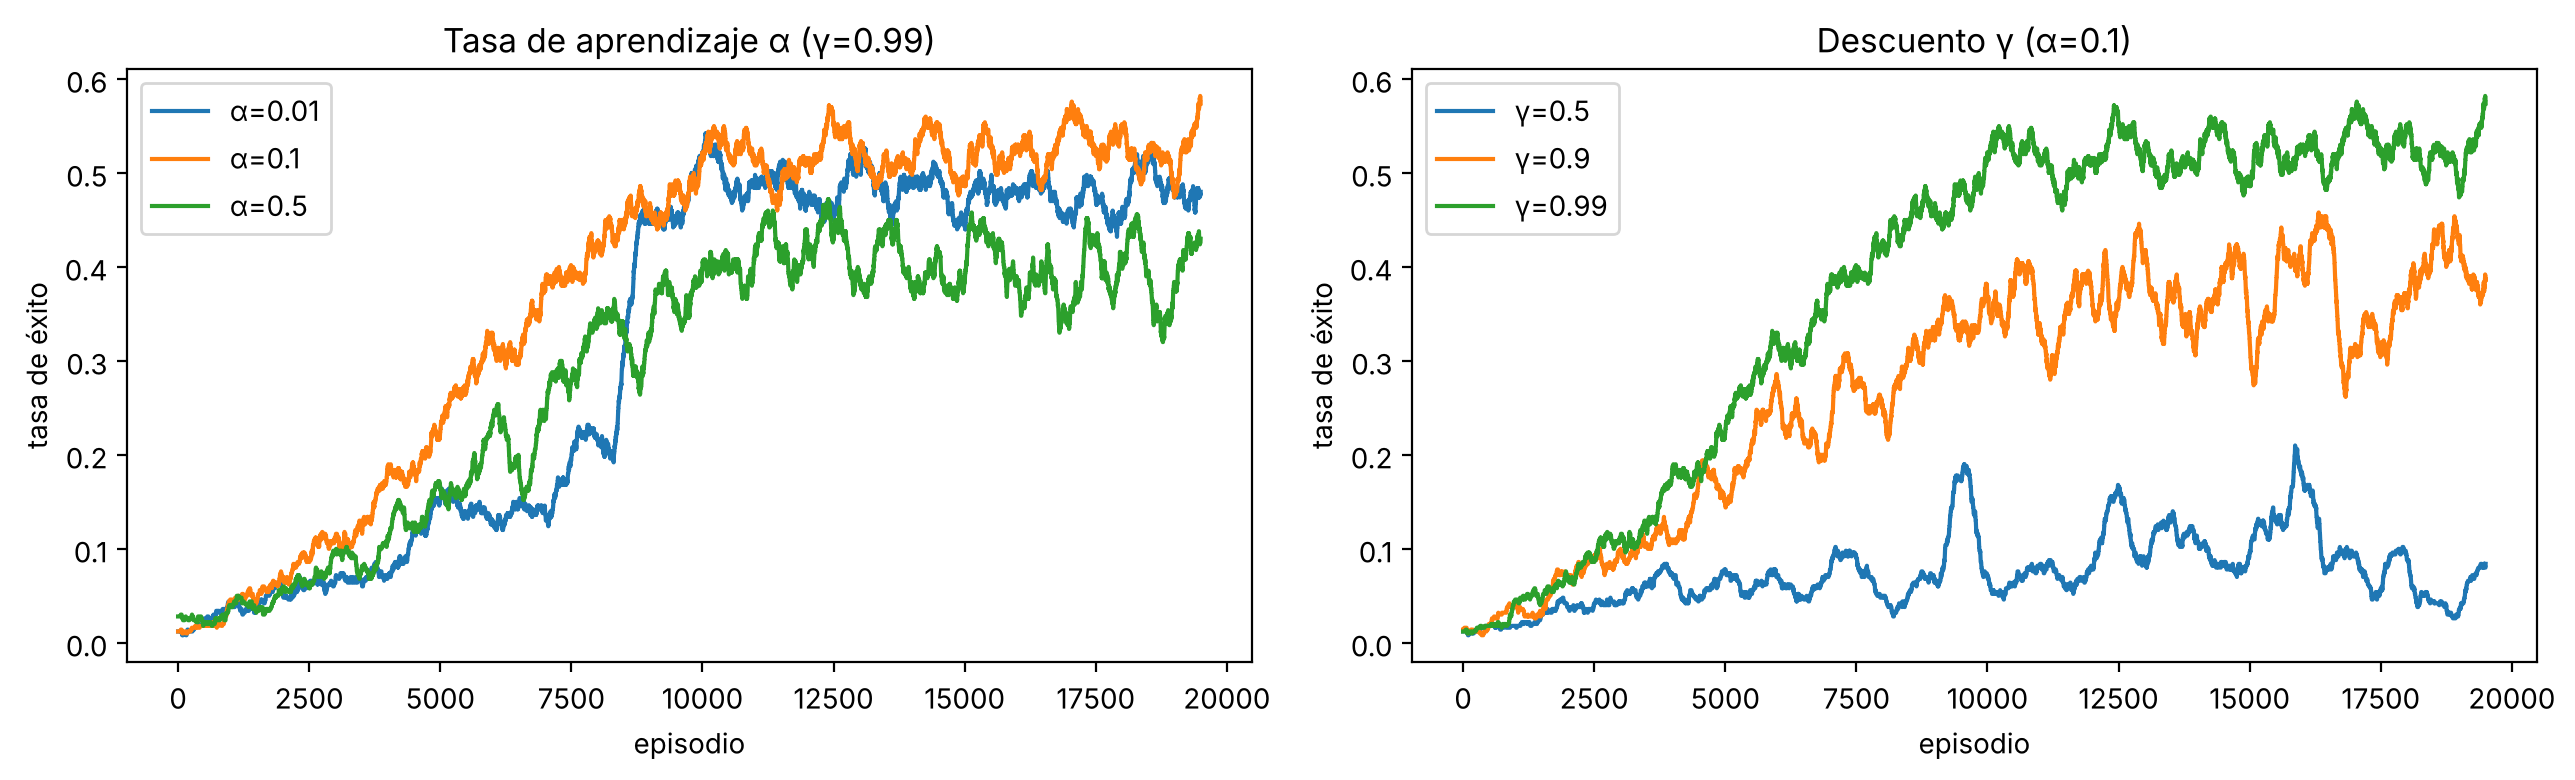

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for alpha in [0.01, 0.1, 0.5]:
    _, r = q_learning(env, alpha=alpha)
    ax[0].plot(media(r), label=f"α={alpha}")
ax[0].set_title("Tasa de aprendizaje α (γ=0.99)")

for g in [0.5, 0.9, 0.99]:
    _, r = q_learning(env, gamma=g)
    ax[1].plot(media(r), label=f"γ={g}")
ax[1].set_title("Descuento γ (α=0.1)")
for a_ in ax:
    a_.set_xlabel("episodio"); a_.set_ylabel("tasa de éxito"); a_.legend()
plt.tight_layout(); plt.show()

- $\alpha$ chico: estable pero lento. $\alpha$ grande: rápido pero ruidoso (el hielo hace que una sola muestra engañe mucho).
- $\gamma$ chico: el agente es miope y no "ve" la meta desde lejos (igual que en la S17).

**Mi explicación (sección 7).**
Con $\alpha=0.1$ se obtiene la mejor curva. Con $\alpha=0.01$ casi no aprende durante los primeros 8,000 episodios y luego sube de golpe hasta 0.5; con $\alpha=0.5$ sube rápido al principio pero se queda más abajo (cerca de 0.4) y oscila mucho, porque cada muestra resbalosa mueve la tabla la mitad del camino.
Para $\gamma$, la diferencia es grande: 0.99 llega a 0.55, 0.9 a unos 0.38 y 0.5 casi no pasa de 0.1. Con un camino seguro de unos 44 pasos, la meta vale $0.9^{44}\approx 0.01$ o $0.5^{44}\approx 0$ vista desde la salida, así que el agente prefiere caminos cortos y arriesgados o directamente no distingue entre acciones.

## 8. Un entorno de trading propio

Heredamos de `gym.Env` y cumplimos el contrato. Usamos precios sintéticos (semilla 42) para no depender de descargas.

- Acciones: `0` corto, `1` fuera, `2` largo  →  posición $\in\{-1,0,+1\}$
- Observación: los últimos `window` rendimientos (hasta $t-1$) y la posición actual
- Recompensa: $\text{pnl}_t = \text{pos}_t\,(p_{t+1}-p_t) - c\,|\Delta\text{pos}|\,p_t$, escalada por el capital inicial
- `terminated` = ruina (equity < 50%); `truncated` = se acabaron los datos

In [11]:
from gymnasium import spaces

class TradingEnv(gym.Env):
    def __init__(self, df, window=30, cost=0.001, init_cash=100_000):
        super().__init__()
        self.df, self.window, self.cost, self.init_cash = df, window, cost, init_cash
        self.action_space = spaces.Discrete(3)                       # 0 corto, 1 fuera, 2 largo
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(window + 1,), dtype=np.float32)

    def _obs(self):
        rets = self.df["ret"].iloc[self.t - self.window : self.t].values   # solo hasta t-1
        return np.append(rets, self.position).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.t, self.position, self.equity = self.window, 0, self.init_cash
        return self._obs(), {}

    def step(self, action):
        target = int(action) - 1                                      # {0,1,2} -> {-1,0,+1}
        p_now, p_next = self.df["close"].iloc[self.t], self.df["close"].iloc[self.t + 1]
        costo = self.cost * abs(target - self.position) * p_now       # costo sobre el CAMBIO de posición
        pnl = target * (p_next - p_now) - costo
        self.equity += pnl
        self.position = target
        self.t += 1
        terminated = bool(self.equity <= 0.5 * self.init_cash)        # ruina
        truncated = bool(self.t >= len(self.df) - 1)                  # fin de datos
        return self._obs(), pnl / self.init_cash, terminated, truncated, {"equity": self.equity}

rng = np.random.default_rng(SEED)
precio = 100 * np.exp(np.cumsum(rng.normal(0.0003, 0.01, 500)))
df = pd.DataFrame({"close": precio})
df["ret"] = df["close"].pct_change().fillna(0.0)

**Primero se valida el entorno, después el agente.** Dos pruebas:
1. `check_env` de Gymnasium revisa que se cumpla el contrato (tipos, espacios, semillas).
2. Buy-and-hold debe ganar exactamente lo que se movió el activo (menos el costo de entrar). Si no, el entorno está mal y ningún agente lo arregla.

In [12]:
from gymnasium.utils.env_checker import check_env

import warnings
warnings.filterwarnings("ignore", message=".*infinity.*")     # Box(-inf, inf) es intencional

env_tr = TradingEnv(df)
check_env(env_tr, skip_render_check=True)
print("check_env: OK")

def correr(env, politica, semilla=SEED):
    obs, _ = env.reset(seed=semilla)
    terminado = truncado = False
    while not (terminado or truncado):
        obs, r, terminado, truncado, info = env.step(politica(obs))
    return info["equity"], terminado, truncado

env_tr.action_space.seed(SEED)
eq_bh, term, trunc = correr(env_tr, lambda obs: 2)                       # siempre largo
eq_rnd, _, _ = correr(env_tr, lambda obs: env_tr.action_space.sample())  # aleatorio

w0, cost = env_tr.window, env_tr.cost
esperado = env_tr.init_cash + (precio[-1] - precio[w0]) - cost * precio[w0]
print(f"buy-and-hold: equity final {eq_bh:,.4f}  esperado {esperado:,.4f}  ¿iguales? {np.isclose(eq_bh, esperado)}")
print(f"  terminó por: terminated={term}, truncated={trunc}")
print(f"aleatorio:    equity final {eq_rnd:,.4f}   (paga costo en cada cambio de posición)")

check_env: OK
buy-and-hold: equity final 100,005.0586  esperado 100,005.0586  ¿iguales? True
  terminó por: terminated=False, truncated=True
aleatorio:    equity final 99,956.8923   (paga costo en cada cambio de posición)


**Para verificar en tu propio entorno:** la observación en $t$ usa solo barras hasta $t-1$; la recompensa usa $p_{t+1}-p_t$ con la posición ya tomada; el costo se cobra sobre el cambio de posición, no sobre la posición.

**Mi explicación (sección 8).**
`check_env` no marcó errores: el entorno respeta tipos, espacios y semillas. Buy-and-hold termina con 100,005.0586, exactamente lo esperado (movimiento del precio menos el costo de entrar), y acabó por `truncated` (se acabaron los datos), no por ruina. El agente aleatorio pierde unos 43 dólares solo por pagar comisión en cada cambio de posición.
Hay que notar dos cosas. Primero, la posición es de una sola acción (unos 100 dólares) contra un capital de 100,000, así que las recompensas son del orden de $10^{-5}$ y la ruina es prácticamente imposible. Segundo, el notebook calcula `pnl = target * (p_next - p_now)` (la posición recién elegida), mientras que la diapositiva 21 usa `self.position` (la posición anterior). Ninguna de las dos hace look-ahead, porque la observación en $t$ solo trae rendimientos hasta $t-1$; la versión de la diapositiva simplemente agrega un rezago de una barra.

## 9. Por qué la tabla no escala a trading

FrozenLake: 16 estados × 4 acciones = 64 números. Un estado de mercado modesto, discretizado, explota:

In [13]:
def tamano_tabla(n_features, bins, n_posiciones=3, n_acciones=3):
    return bins ** n_features * n_posiciones * n_acciones

for nf, b in [(2, 10), (6, 8), (8, 10)]:
    n = tamano_tabla(nf, b)
    print(f"{nf} features × {b:2d} bins -> {n:>15,} entradas  ·  10 visitas c/u = {10*n/252:>14,.0f} años de barras diarias")

2 features × 10 bins ->             900 entradas  ·  10 visitas c/u =             36 años de barras diarias
6 features ×  8 bins ->       2,359,296 entradas  ·  10 visitas c/u =         93,623 años de barras diarias
8 features × 10 bins ->     900,000,000 entradas  ·  10 visitas c/u =     35,714,286 años de barras diarias


**Mi explicación (sección 9).**
El tamaño de la tabla crece exponencialmente con el número de features: con 2 features y 10 bins son 900 entradas (36 años de datos diarios para visitar cada una 10 veces), con 6 features y 8 bins son 2.36 millones (93,623 años) y con 8 features y 10 bins son 900 millones.
Además el cálculo es optimista, porque supone que todas las celdas se visitan por igual; en la práctica los estados de mercado se concentran en unas pocas regiones y la mayoría de las celdas nunca se ven. Esto se calcula con detalle en la pregunta 6 y se prueba en el ejercicio (c).

**Dos fallas:** (1) memoria: la tabla no cabe; (2) generalización: dos estados de mercado casi iguales son celdas independientes,
lo que aprende en una no le enseña nada de la otra. La solución es una función $Q_\theta(s,a)$ que interpole: la red de la S19 (DQN).

**Para llevar**
1. Model-free = cambiar la esperanza de Bellman por muestras $(s,a,r,s')$.
2. Q-Learning usa $\max$ → off-policy → aprende $Q^\star$ aunque explore.
3. SARSA usa la acción tomada → on-policy → cauteloso.
4. `terminated` sin bootstrap; `truncated` con bootstrap.
5. Valida el entorno (aleatorio y buy-and-hold) antes de entrenar.

**Ejercicios:** (a) repite la sección 4 con `is_slippery=False`; (b) agrega una recompensa de $-0.01$ por paso con un `gym.RewardWrapper` y observa la política;
(c) discretiza dos features de `TradingEnv` (último rendimiento y posición) y corre Q-Learning tabular: documenta dónde se rompe.

---
# Parte 2. Preguntas de investigación

Las fuentes están al final de esta parte. Donde pude, agregué un experimento corto con el mismo código del notebook (semilla 42) para respaldar la respuesta.

## Pregunta 1. Monte Carlo vs. TD

Para la misma transición desde $s_t$, los dos métodos usan la misma regla $V(s_t)\leftarrow V(s_t)+\alpha\,[\text{target}-V(s_t)]$ pero con distinto target (Sutton y Barto, 2018, cap. 5 y 6):

- Monte Carlo: $\;G_t = r_{t+1}+\gamma r_{t+2}+\gamma^2 r_{t+3}+\dots+\gamma^{T-t-1}r_T$, el retorno real hasta el final del episodio.
- TD(0): $\;r_{t+1}+\gamma V(s_{t+1})$, una recompensa real y el resto se reemplaza por la estimación actual.

**Sesgo:** el target de MC es una muestra real de $\mathbb{E}[G_t]$, así que no tiene sesgo; el de TD sí, porque usa $V(s_{t+1})$, que todavía puede estar mal.
**Varianza:** $G_t$ suma muchas recompensas aleatorias y cada una agrega ruido, mientras que el target de TD solo depende de una transición aleatoria, así que su varianza es mucho menor.

**Bootstrapping** es actualizar una estimación usando otra estimación (TD lo hace con $V(s_{t+1})$; MC no).

**TD($\lambda$)** (Sutton y Barto, 2018, cap. 12) usa como target el $\lambda$-return, un promedio ponderado de los retornos de $n$ pasos:
$G_t^\lambda=(1-\lambda)\sum_{n\ge1}\lambda^{n-1}G_{t:t+n}$. Con $\lambda=0$ todo el peso cae en $G_{t:t+1}=r_{t+1}+\gamma V(s_{t+1})$, es decir TD(0); con $\lambda=1$ el peso se va al retorno completo y se obtiene Monte Carlo. Valores intermedios negocian entre sesgo y varianza.

Para verlo con números, tomé la política aprendida en la sección 4 y comparé los dos targets para la **misma** transición inicial (desde la celda 0) en 2000 episodios:

In [14]:
V_ql = Q_ql.max(axis=1)
env.reset(seed=SEED)
target_mc, target_td = [], []
for _ in range(2000):
    s, _ = env.reset()
    s1, r1, term, trunc, _ = env.step(int(pi_ql[s]))
    target_td.append(r1 + gamma * (0.0 if term else V_ql[s1]))   # TD(0): una recompensa + estimación
    G, k, s_ = r1, 1, s1                                          # MC: seguimos jugando hasta el final
    while not (term or trunc):
        s_, r, term, trunc, _ = env.step(int(pi_ql[s_]))
        G += gamma**k * r
        k += 1
    target_mc.append(G)
target_mc, target_td = np.array(target_mc), np.array(target_td)

print(f"{'':16s}  media   desv. est.   min    max")
for nombre, x in [("Monte Carlo G_0", target_mc), ("TD(0)", target_td)]:
    print(f"{nombre:16s}  {x.mean():.3f}   {x.std():8.3f}   {x.min():.3f}  {x.max():.3f}")
print(f"V*(0) de DP = {Q_star[0].max():.3f}   V_ql(0) estimado = {V_ql[0]:.3f}")

                  media   desv. est.   min    max
Monte Carlo G_0   0.524      0.334   0.000  0.951
TD(0)             0.584      0.006   0.580  0.593
V*(0) de DP = 0.542   V_ql(0) estimado = 0.586


**Resultado.** Los dos targets estiman lo mismo (el valor de la celda 0), pero se comportan muy distinto. El de Monte Carlo vale 0 si el episodio acaba en un hoyo o se trunca y $\gamma^{k}$ si llega a la meta en $k+1$ pasos; por eso va de 0.000 a 0.951 con desviación estándar 0.334. El de TD(0) solo depende de a dónde resbaló el primer paso, así que su desviación es 0.006, unas 55 veces menor.
A cambio, TD hereda el error de la tabla: su media (0.584) está pegada a $V_{ql}(0)=0.586$, que sobreestima $V^\star(0)=0.542$. La media de MC (0.524) no depende de la tabla. Queda un poco debajo de 0.542 porque cerca de 10% de los episodios se cortan a los 100 pasos con retorno 0 (más el ruido de muestreo); es decir, estima el retorno del juego tal como se juega. Es justo la diferencia de sesgo y varianza de la diapositiva 9.

## Pregunta 2. Convergencia

Las condiciones de Robbins y Monro (1951), que Sutton y Barto (2018, sec. 2.5, ec. 2.7) usan para los pasos de aprendizaje, piden que para cada par $(s,a)$:

$$\sum_{n=1}^{\infty}\alpha_n(s,a)=\infty \qquad\text{y}\qquad \sum_{n=1}^{\infty}\alpha_n^2(s,a)<\infty .$$

La primera garantiza que los pasos sean lo bastante grandes para llegar a cualquier valor sin importar dónde empiece la tabla; la segunda, que al final sean lo bastante chicos para que el ruido de las muestras se apague.

**El $\alpha=0.1$ fijo del notebook no las cumple.** La primera sí ($0.1+0.1+\dots=\infty$), pero la segunda no ($0.01+0.01+\dots=\infty$). Con $\alpha$ fijo, $Q$ no converge en sentido estricto: sigue oscilando alrededor de $Q^\star$ con un ruido proporcional a $\alpha$ y a la varianza de las transiciones, que es lo que se ve en la curva de la sección 4 y en los valores que no coinciden con $Q^\star$. Un ejemplo de pasos que sí cumplen las condiciones es $\alpha_n = 1/n^{p}$ con $0.5<p\le1$, donde $n$ es el número de visitas a $(s,a)$.

**La otra condición** (Watkins y Dayan, 1992) es que **cada par $(s,a)$ se visite infinitas veces**, lo que exige explorar para siempre (por eso el notebook deja $\varepsilon_{\min}=0.05$ y no 0). También se piden recompensas acotadas y $\gamma<1$ (o un problema episódico que siempre termine). Con eso, Q-Learning converge a $Q^\star$ con probabilidad 1 (ver también Jaakkola, Jordan y Singh, 1994).

Lo comprobé comparando el error contra $Q^\star$ con $\alpha$ fijo y con $\alpha_n=1/n^{0.6}$, con la misma semilla y el mismo esquema de $\varepsilon$:

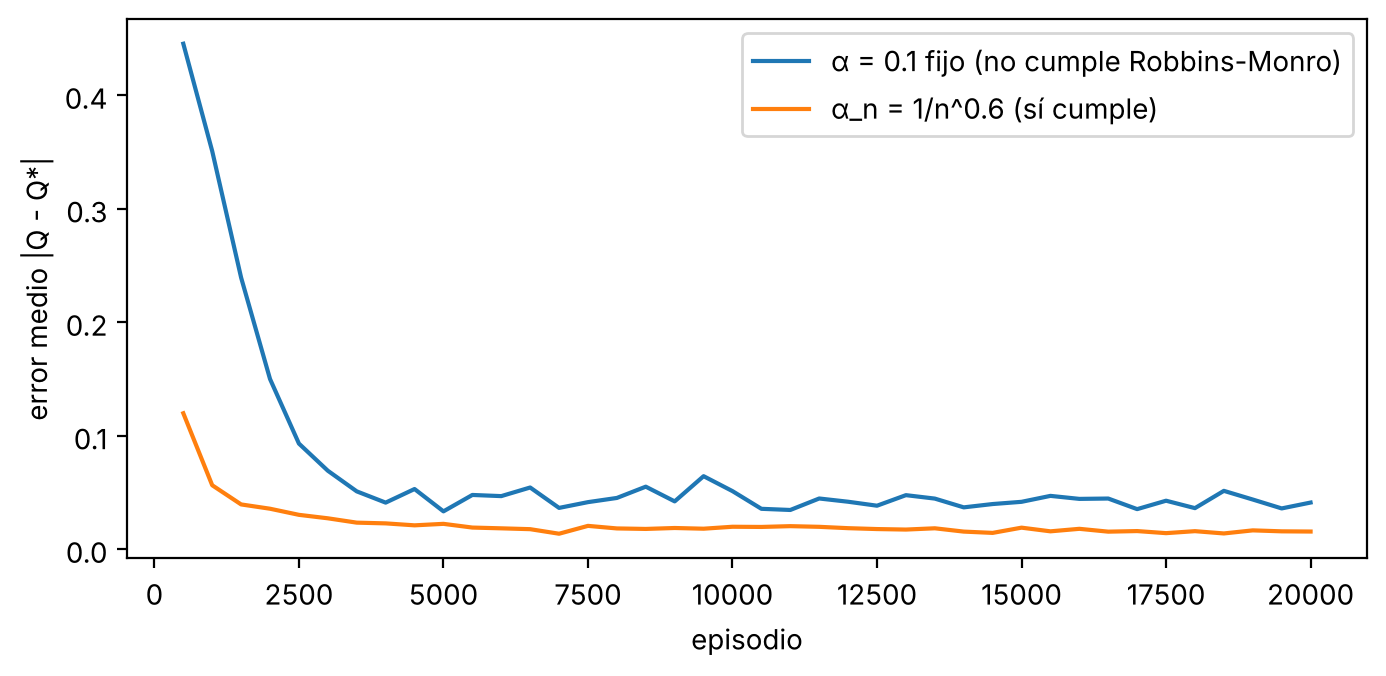

α fijo 0.1    error final 0.0411   éxito greedy 75.1%


α = 1/n^0.6   error final 0.0156   éxito greedy 75.1%


In [15]:
def q_learning_alpha(env, episodios=20_000, alpha_fijo=0.1, alpha_fn=None, gamma=0.99,
                     eps=1.0, eps_min=0.05, decay=0.9997, cada=500, semilla=SEED):
    # Q-Learning con paso alpha fijo o alpha_n = alpha_fn(n), n = visitas a (s,a).
    # Devuelve Q y el error medio |Q - Q*| (estados no terminales) cada `cada` episodios.
    rng = np.random.default_rng(semilla)
    Q, N = np.zeros((nS, nA)), np.zeros((nS, nA))
    errores = []
    env.reset(seed=semilla)
    for ep in range(episodios):
        s, _ = env.reset()
        terminado = truncado = False
        while not (terminado or truncado):
            a = int(rng.integers(nA)) if rng.random() < eps else int(Q[s].argmax())
            s2, r, terminado, truncado, _ = env.step(a)
            N[s, a] += 1
            alpha = alpha_fijo if alpha_fn is None else alpha_fn(N[s, a])
            futuro = 0.0 if terminado else Q[s2].max()
            Q[s, a] += alpha * (r + gamma * futuro - Q[s, a])
            s = s2
        eps = max(eps_min, eps * decay)
        if (ep + 1) % cada == 0:
            errores.append(np.abs(Q - Q_star)[no_term].mean())
    return Q, np.array(errores)

Q_fijo, err_fijo = q_learning_alpha(env)
Q_rm, err_rm = q_learning_alpha(env, alpha_fn=lambda n: 1 / n**0.6)

x = np.arange(1, len(err_fijo) + 1) * 500
plt.figure(figsize=(8, 3.5))
plt.plot(x, err_fijo, label="α = 0.1 fijo (no cumple Robbins-Monro)")
plt.plot(x, err_rm, label="α_n = 1/n^0.6 (sí cumple)")
plt.xlabel("episodio"); plt.ylabel("error medio |Q - Q*|"); plt.legend(); plt.show()

for nombre, Q, e in [("α fijo 0.1", Q_fijo, err_fijo), ("α = 1/n^0.6", Q_rm, err_rm)]:
    print(f"{nombre:12s}  error final {e[-1]:.4f}   éxito greedy {simular_politica(env, Q.argmax(1), semilla=SEED):.1%}")

**Resultado.** Con $\alpha$ fijo el error baja rápido, pero se estanca alrededor de 0.04 y sigue brincando hasta el final (0.0411): cada actualización mueve la tabla 10% hacia una sola muestra resbalosa y ese ruido nunca se apaga. Con $\alpha_n=1/n^{0.6}$ el error baja a 0.0156, casi tres veces menos, y la curva es mucho más suave. La política greedy es la misma en los dos casos (75.1%): para escoger acciones alcanzó el $\alpha$ fijo, pero los valores solo se acercan a $Q^\star$ cuando el paso decrece.
El error tampoco llega a 0 con $\alpha_n$ decreciente, porque con $\varepsilon_{\min}=0.05$ las acciones malas se visitan poco; el teorema es asintótico y 20,000 episodios no son infinitos.
En trading a veces se usa un $\alpha$ fijo a propósito, porque el mercado no es estacionario y conviene que el agente siga adaptándose a datos recientes (Sutton y Barto, 2018, sec. 2.5). El costo es que las estimaciones siempre tienen ruido.

## Pregunta 3. On-policy vs. off-policy

El único símbolo que cambia está en el target: Q-Learning usa $\max_{a'}Q(s',a')$ y SARSA usa $Q(s',a')$ con la $a'$ que realmente eligió (Sutton y Barto, 2018, sec. 6.4 y 6.5; Rummery y Niranjan, 1994).
Ese cambio decide **qué política se está evaluando**. Con el `max`, Q-Learning aprende el valor de la política greedy aunque se comporte con $\varepsilon$-greedy (aprende una política distinta a la que usa para generar datos, es **off-policy**). SARSA aprende el valor de la misma política $\varepsilon$-greedy con la que actúa (es **on-policy**), así que el costo de sus errores de exploración queda dentro de $Q$.

**Cliff Walking (Sutton y Barto, 2018, ej. 6.6).** Es un tablero de 4x12: se sale abajo a la izquierda y la meta está abajo a la derecha; entre las dos hay un acantilado. Cada paso da $-1$ y caer da $-100$ y regresa a la salida. Con $\varepsilon=0.1$, el libro muestra que Q-Learning aprende el camino óptimo pegado al borde pero, al explorar, a veces se cae, así que su recompensa en línea es peor; SARSA aprende un camino más largo y alejado del borde y obtiene más recompensa mientras aprende.
Lo reproduje con `CliffWalking-v1` de Gymnasium, con los parámetros del libro ($\alpha=0.5$, $\gamma=1$, $\varepsilon=0.1$, 500 episodios) y 20 corridas con semillas 42 a 61. Incluyo Expected SARSA porque lo uso en la pregunta 4.

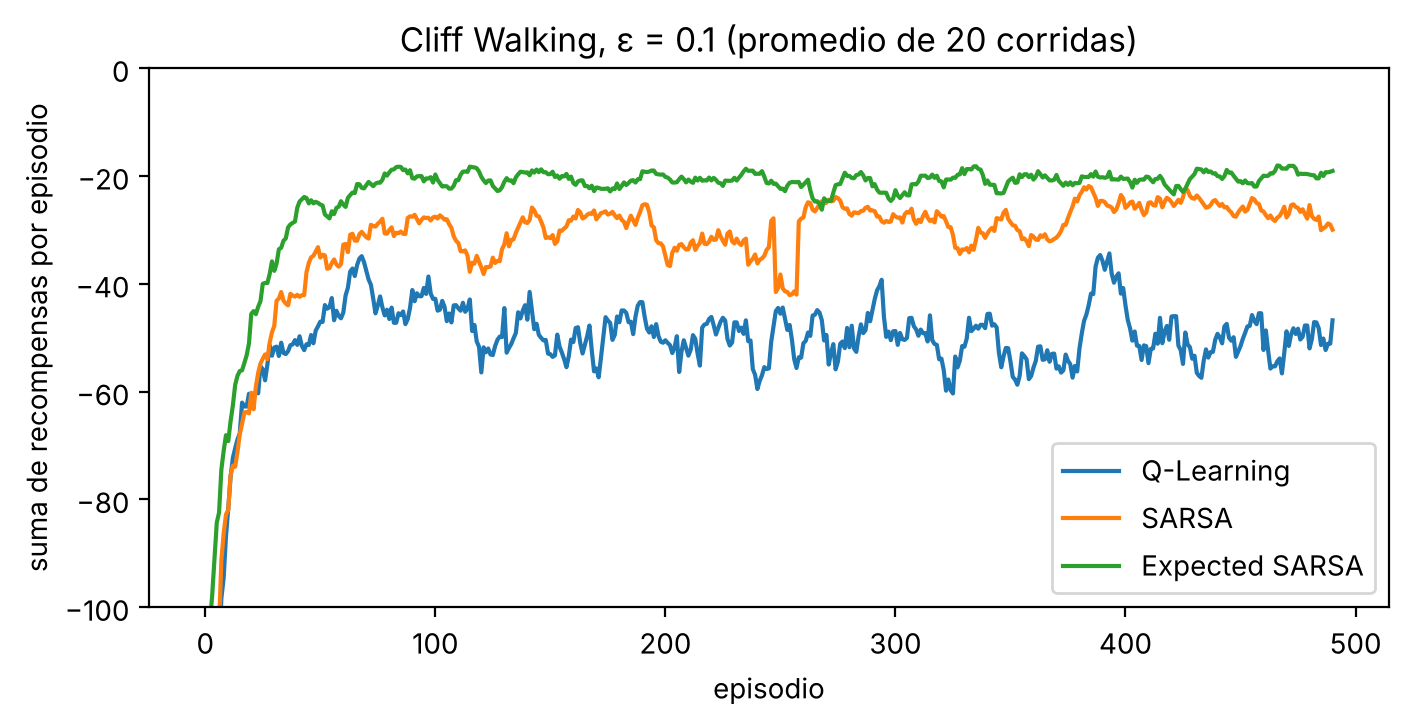

Q-Learning      recompensa media en línea (últimos 100 episodios):  -49.9
SARSA           recompensa media en línea (últimos 100 episodios):  -26.1
Expected SARSA  recompensa media en línea (últimos 100 episodios):  -20.2

Camino greedy aprendido por Q-Learning (semilla 42):
. . . . . . . . . . . .
. . . . . . . . . . . .
* * * * * * * * * * * *
S C C C C C C C C C C G

Camino greedy aprendido por SARSA (semilla 42):
* * * * * * * * * * * *
* . . . . . . . . . . *
* . . . . . . . . . . *
S C C C C C C C C C C G


In [16]:
def control_td(env, episodios=500, alpha=0.5, gamma=1.0, eps=0.1, metodo="q", semilla=SEED):
    # Control TD tabular con epsilon fijo: "q" (Q-Learning), "sarsa" o "esarsa" (Expected SARSA).
    nS_, nA_ = env.observation_space.n, env.action_space.n
    rng = np.random.default_rng(semilla)
    Q = np.zeros((nS_, nA_))
    def elegir(s):                                       # empates al azar para no sesgar hacia la acción 0
        if rng.random() < eps:
            return int(rng.integers(nA_))
        return int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))
    retornos = []
    env.reset(seed=semilla)
    for ep in range(episodios):
        s, _ = env.reset()
        a = elegir(s)
        terminado = truncado = False
        G = 0.0
        while not (terminado or truncado):
            s2, r, terminado, truncado, _ = env.step(a)
            G += r
            a2 = elegir(s2)
            if metodo == "q":
                futuro = Q[s2].max()
            elif metodo == "sarsa":
                futuro = Q[s2, a2]
            else:                                        # esperanza bajo la política epsilon-greedy
                pi = np.full(nA_, eps / nA_)
                pi[Q[s2].argmax()] += 1 - eps
                futuro = pi @ Q[s2]
            if terminado:
                futuro = 0.0
            Q[s, a] += alpha * (r + gamma * futuro - Q[s, a])
            s, a = s2, a2
        retornos.append(G)
    return Q, np.array(retornos)

def camino_greedy(env, Q, max_pasos=60):
    # Dibuja en texto el camino de la política greedy (C = acantilado, * = camino).
    filas, cols = env.unwrapped.shape
    s, _ = env.reset(seed=SEED)
    tablero = np.full((filas, cols), ".")
    tablero[3, 1:-1] = "C"
    tablero[3, 0], tablero[3, -1] = "S", "G"
    for _ in range(max_pasos):
        s, _, terminado, _, _ = env.step(int(Q[s].argmax()))
        i, j = divmod(int(s), cols)
        if tablero[i, j] == ".":
            tablero[i, j] = "*"
        if terminado:
            break
    return "\n".join(" ".join(f) for f in tablero)

env_cw = gym.make("CliffWalking-v1")
nombres = {"q": "Q-Learning", "sarsa": "SARSA", "esarsa": "Expected SARSA"}
res_cw, Q_cw = {}, {}
for m in nombres:
    corridas = [control_td(env_cw, metodo=m, semilla=SEED + k) for k in range(20)]
    res_cw[m] = np.array([r for _, r in corridas])
    Q_cw[m] = corridas[0][0]                             # tabla de la corrida con semilla 42

plt.figure(figsize=(8, 3.5))
suav = lambda x: np.convolve(x, np.ones(10) / 10, mode="valid")
for m, nombre in nombres.items():
    plt.plot(suav(res_cw[m].mean(0)), label=nombre)
plt.ylim(-100, 0); plt.xlabel("episodio"); plt.ylabel("suma de recompensas por episodio")
plt.title("Cliff Walking, ε = 0.1 (promedio de 20 corridas)"); plt.legend(); plt.show()

for m, nombre in nombres.items():
    print(f"{nombre:15s} recompensa media en línea (últimos 100 episodios): {res_cw[m][:, -100:].mean():6.1f}")
for m in ["q", "sarsa"]:
    print(f"\nCamino greedy aprendido por {nombres[m]} (semilla 42):")
    print(camino_greedy(env_cw, Q_cw[m]))

**Resultado.** Se reproduce lo que reporta el libro: en los últimos 100 episodios SARSA obtiene −26.1 por episodio y Q-Learning −49.9. Los caminos lo explican. Q-Learning aprendió el camino óptimo de 13 pasos, en la fila justo arriba del acantilado, y como sigue explorando con $\varepsilon=0.1$, de vez en cuando un paso al azar lo tira (−100). SARSA aprendió a subir hasta la fila de arriba, un camino de 17 pasos, porque sus valores ya incluyen la probabilidad de que un paso aleatorio cerca del borde lo haga caer.

**Relación con la sección 6.** Es el mismo fenómeno en otro entorno. En FrozenLake, SARSA estimó $V(0)=0.277$ contra 0.558 de Q-Learning: SARSA mide el valor de su política con exploración y Q-Learning el de la greedy. La diferencia es que en FrozenLake no hay un camino "seguro pero más largo" que proteja de la exploración (el hielo resbala en todas partes), así que la cautela de SARSA no le dio ventaja en línea (37.1% contra 39.6%) y su política greedy salió peor (63.5% contra 74.2%). En Cliff Walking el riesgo está concentrado en un borde que se puede evitar, y ahí la cautela sí paga.
En trading, si el agente aprende operando con dinero real, el "acantilado" son las pérdidas por explorar y SARSA es la opción más prudente; si explora en un simulador y solo se despliega la política final, conviene Q-Learning.

## Pregunta 4. Expected SARSA y Double Q-Learning

**Expected SARSA** (van Seijen et al., 2009; Sutton y Barto, 2018, sec. 6.6) reemplaza la acción muestreada de SARSA por su esperanza bajo la política:
$$Q(s,a)\leftarrow Q(s,a)+\alpha\Big[r+\gamma\sum_{a'}\pi(a'|s')\,Q(s',a')-Q(s,a)\Big].$$
Así elimina la varianza que viene de elegir $a'$ al azar. Si $\pi$ es greedy, la suma es el `max` y se obtiene Q-Learning; por eso se puede ver como una generalización de los dos. En el Cliff Walking de arriba obtuvo la mejor recompensa en línea.

**El problema del `max`: maximization bias** (Thrun y Schwartz, 1993; Sutton y Barto, 2018, sec. 6.7). Si las estimaciones $\hat Q(s',a')$ son ruidosas, aunque cada una sea insesgada se cumple $\mathbb{E}[\max_a \hat Q(s',a)]\ge\max_a\mathbb{E}[\hat Q(s',a)]$: el máximo tiende a escoger justo la acción cuyo ruido salió positivo. Q-Learning mete ese máximo en el target y el error se propaga hacia atrás, así que **sobreestima** los valores.

**Double Q-Learning** (van Hasselt, 2010) mantiene dos tablas $Q_A$ y $Q_B$; en cada paso elige una al azar para actualizar, usa esa tabla para **escoger** la mejor acción y la otra para **evaluarla**:
$$Q_A(s,a)\leftarrow Q_A(s,a)+\alpha\big[r+\gamma\,Q_B\big(s',\arg\max_{a'}Q_A(s',a')\big)-Q_A(s,a)\big].$$
Como el ruido de $Q_B$ es independiente del que llevó a elegir esa acción, la estimación deja de estar sesgada hacia arriba (puede quedar un poco hacia abajo).

Lo probé con el ejemplo 6.7 de Sutton y Barto, que se parece mucho a un problema de trading. Desde A, "derecha" termina con recompensa 0 (no operar). "Izquierda" lleva a B, donde hay 10 acciones (10 estrategias) cuya recompensa es $\mathcal{N}(-0.1, 1)$: todas pierden en promedio. Lo correcto es casi nunca ir a la izquierda (5% por la exploración). Usé 1000 corridas de 300 episodios, $\alpha=0.1$, $\varepsilon=0.1$, $\gamma=1$ y un solo generador con semilla 42.

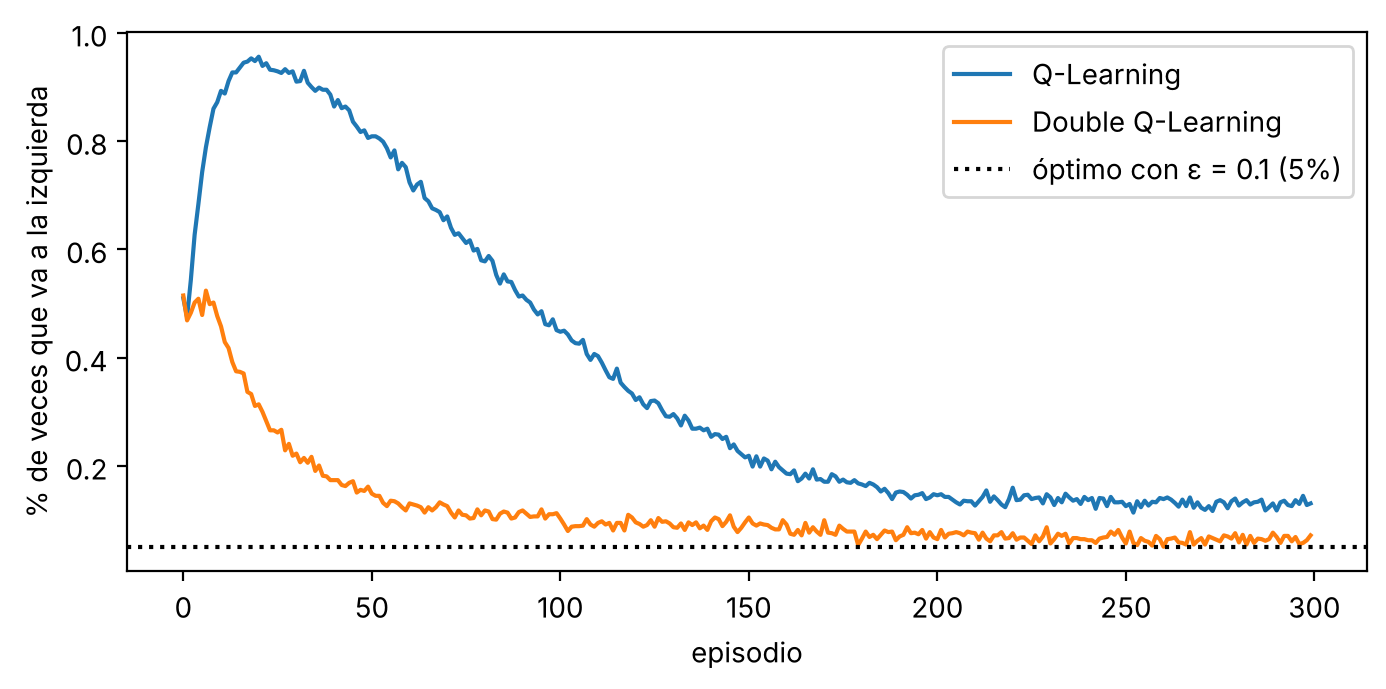

                    máximo   episodio del máximo   últimos 50 episodios
Q-Learning           95.6%                    20      13.1%
Double Q-Learning    52.4%                     6       6.4%


In [17]:
def maximization_bias(metodo="q", n_corridas=1000, episodios=300, alpha=0.1, eps=0.1, n_b=10, semilla=SEED):
    # Ejemplo 6.7 de Sutton y Barto. Devuelve la fracción de corridas que eligieron "izquierda" en A por episodio.
    rng = np.random.default_rng(semilla)
    izquierda = np.zeros((n_corridas, episodios))
    for corrida in range(n_corridas):
        QA = {"A": np.zeros(2), "B": np.zeros(n_b)}
        QB = {"A": np.zeros(2), "B": np.zeros(n_b)}
        def elegir(s):
            q = QA[s] + QB[s] if metodo == "double" else QA[s]
            if rng.random() < eps:
                return int(rng.integers(len(q)))
            return int(rng.choice(np.flatnonzero(q == q.max())))
        for ep in range(episodios):
            a = elegir("A")                               # 0 = izquierda (a B), 1 = derecha (fin, r = 0)
            izquierda[corrida, ep] = (a == 0)
            if a == 1:
                transiciones = [("A", 1, 0.0, None)]
            else:
                b = elegir("B")
                transiciones = [("A", 0, 0.0, "B"), ("B", b, rng.normal(-0.1, 1.0), None)]
            for s, a_, r, s2 in transiciones:
                if metodo == "double":
                    X, Y = (QA, QB) if rng.random() < 0.5 else (QB, QA)
                    futuro = 0.0 if s2 is None else Y[s2][X[s2].argmax()]   # X elige, Y evalúa
                    X[s][a_] += alpha * (r + futuro - X[s][a_])
                else:
                    futuro = 0.0 if s2 is None else QA[s2].max()
                    QA[s][a_] += alpha * (r + futuro - QA[s][a_])
    return izquierda.mean(axis=0)

izq_q = maximization_bias("q")
izq_dq = maximization_bias("double")

plt.figure(figsize=(8, 3.5))
plt.plot(izq_q, label="Q-Learning")
plt.plot(izq_dq, label="Double Q-Learning")
plt.axhline(0.05, color="k", ls=":", label="óptimo con ε = 0.1 (5%)")
plt.xlabel("episodio"); plt.ylabel("% de veces que va a la izquierda"); plt.legend(); plt.show()

print(f"{'':18s}  máximo   episodio del máximo   últimos 50 episodios")
for nombre, x in [("Q-Learning", izq_q), ("Double Q-Learning", izq_dq)]:
    print(f"{nombre:18s}  {x.max():6.1%}   {x.argmax():19d}   {x[-50:].mean():8.1%}")

**Resultado.** Q-Learning llega a ir a la izquierda en 95.6% de las corridas (episodio 20), aunque ahí todas las acciones pierden en promedio, y después de 300 episodios todavía va 13.1% de las veces, más del doble del 5% óptimo. La causa es el `max`: con 10 acciones con ruido $\mathcal{N}(0,1)$, casi siempre alguna estimación de B sale positiva al principio, el máximo la toma como el valor de B y eso hace que ir a la izquierda parezca mejor que 0. Double Q-Learning nunca pasa de 52.4% (el 50% inicial viene de los empates en 0), baja rápido y termina en 6.4%, muy cerca del óptimo.
La misma huella aparece en el notebook: en la sección 4, Q-Learning con $\alpha$ fijo terminó con Q(0,←)=0.59 y Q(14,↓)=0.90, contra 0.54 y 0.86 de $Q^\star$, y en la pregunta 1 $V_{ql}(0)=0.586$ contra 0.542.

**Por qué importa en trading.** En mercados el ruido es enorme comparado con la señal (en `TradingEnv` el drift diario es 0.03% y la volatilidad 1%). Un agente que elige entre varias acciones o estrategias con el máximo de estimaciones ruidosas siempre va a encontrar alguna que "parece" rentable aunque ninguna lo sea. Eso tiene tres consecuencias: sobreestima el P&L esperado, opera de más (en el ejemplo va a B cuando lo mejor es no hacer nada) y abre posiciones reales por puro ruido. Es el mismo problema que el sesgo de selección al probar muchas estrategias en un backtest y quedarse con la mejor (Bailey y López de Prado, 2014). El ejercicio (c) lo muestra: con 50 bins el agente "encuentra" una estrategia que gana 78.58 USD en entrenamiento y pierde 8.07 USD en prueba.

## Pregunta 5. `terminated` vs. `truncated`

Hasta Gym 0.25, `step` devolvía una sola bandera `done`. El problema es que `done=True` mezclaba dos situaciones muy distintas: que el episodio terminara de verdad (estado terminal, el futuro vale 0) o que se acabara el tiempo (el futuro sí existe, solo dejamos de mirar). La mayoría de las implementaciones hacían `target = r` siempre que `done` era verdadero, así que también cortaban el bootstrap al llegar al límite de tiempo. Pardo et al. (2018) mostraron que eso introduce un sesgo y vuelve el problema no markoviano, porque el mismo estado a veces "vale" su futuro y a veces 0 dependiendo de un reloj que el agente no observa. Gym 0.26 (2022) separó la bandera en `terminated` y `truncated` para que el algoritmo pueda distinguirlas, y Gymnasium heredó esa API (Towers et al., 2024; documentación de Gymnasium, "Handling Time Limits").

**Qué aprende un agente si el último bar se marca como `terminated`.** Aprende que el mundo se acaba en esa fecha y que todo lo que pase después vale 0. Los estados que aparecen cerca del final se subvalúan, y como en la observación no está el tiempo restante, ese error se propaga a estados iguales que aparecen a la mitad del histórico. En trading esto se traduce en cerrar posiciones antes del final por una razón que no tiene nada que ver con el mercado, y en valores menores a los reales.

**Evidencia de la sección 5.** Ahí vimos el error contrario: no cortar el bootstrap cuando sí hay `terminated` infla los valores (máximo 1.768 > 1 con $Q_0=1$) aunque la política greedy se vea bien. El error de esta pregunta es el espejo: cortar el bootstrap cuando solo hay `truncated` los desinfla. Lo probé en FrozenLake, donde $\pi^\star$ llega al límite de 100 pasos en cerca de 10% de los episodios, cambiando solo la condición del bootstrap:

In [18]:
def q_learning_trunc(env, episodios=20_000, alpha=0.1, gamma=0.99, eps=1.0, eps_min=0.05,
                     decay=0.9997, cortar_truncado=False, semilla=SEED):
    # Igual que q_learning (metodo="q"), pero con la opción de tratar truncated como terminated (el error).
    rng = np.random.default_rng(semilla)
    Q = np.zeros((nS, nA))
    elegir = lambda s: int(rng.integers(nA)) if rng.random() < eps else int(Q[s].argmax())
    env.reset(seed=semilla)
    n_trunc = 0
    for ep in range(episodios):
        s, _ = env.reset()
        a = elegir(s)
        terminado = truncado = False
        while not (terminado or truncado):
            s2, r, terminado, truncado, _ = env.step(a)
            a2 = elegir(s2)
            futuro = Q[s2].max()
            if terminado or (truncado and cortar_truncado):
                futuro = 0.0
            Q[s, a] += alpha * (r + gamma * futuro - Q[s, a])
            s, a = s2, a2
        n_trunc += truncado
        eps = max(eps_min, eps * decay)
    return Q, n_trunc

def resumen_politica(env, politica, n_episodios=2000, semilla=SEED):
    # Éxito, largo medio y % de episodios truncados siguiendo una política fija.
    env.reset(seed=semilla)
    exitos, largos, truncs = 0, [], 0
    for _ in range(n_episodios):
        s, _ = env.reset()
        terminado = truncado = False
        k = 0
        while not (terminado or truncado):
            s, r, terminado, truncado, _ = env.step(int(politica[s]))
            k += 1
        exitos += r > 0
        largos.append(k)
        truncs += truncado
    return exitos / n_episodios, np.mean(largos), truncs / n_episodios

exito, largo, trunc = resumen_politica(env, pi_star)
print(f"π* en FrozenLake: éxito {exito:.1%}, largo medio {largo:.1f} pasos, truncados {trunc:.1%}\n")

print(f"{'límite':>6s}  {'bootstrap al truncar':22s}  episodios truncados   V(0)    V*(0)   error |Q-Q*|   éxito greedy")
for limite in [100, 20]:
    env_lim = gym.make("FrozenLake-v1", is_slippery=True, max_episode_steps=limite)
    for cortar in [False, True]:
        Q_t, n_t = q_learning_trunc(env_lim, cortar_truncado=cortar)
        etiqueta = "no (error)" if cortar else "sí (correcto)"
        print(f"{limite:6d}  {etiqueta:22s}  {n_t:19,d}   {Q_t[0].max():.3f}   {Q_star[0].max():.3f}   "
              f"{np.abs(Q_t - Q_star)[no_term].mean():12.3f}   {simular_politica(env, Q_t.argmax(1), semilla=SEED):11.1%}")
        if limite == 100 and cortar:
            Q_trunc100 = Q_t

print("\nPolítica con el error (límite 100):")
print(np.array(ACCIONES)[Q_trunc100.argmax(1)].reshape(4, 4))
print("π*:")
print(np.array(ACCIONES)[pi_star].reshape(4, 4))

π* en FrozenLake: éxito 74.2%, largo medio 44.0 pasos, truncados 10.1%

límite  bootstrap al truncar    episodios truncados   V(0)    V*(0)   error |Q-Q*|   éxito greedy


   100  sí (correcto)                           746   0.586   0.542          0.045         74.2%


   100  no (error)                              762   0.492   0.542          0.056         24.5%


    20  sí (correcto)                        10,946   0.544   0.542          0.037         74.2%


    20  no (error)                            9,159   0.178   0.542          0.272         73.5%

Política con el error (límite 100):
[['↓' '↑' '↑' '↑']
 ['←' '←' '←' '←']
 ['↑' '→' '→' '←']
 ['←' '→' '↓' '←']]
π*:
[['←' '↑' '↑' '↑']
 ['←' '←' '←' '←']
 ['↑' '↓' '←' '←']
 ['←' '→' '↓' '←']]


**Resultado.** Con el límite real de 100 pasos, $\pi^\star$ se trunca en 10.1% de los episodios, así que el error no es raro. Si se corta el bootstrap en esos episodios, $V(0)$ baja de 0.586 a 0.492 y la política greedy cae de 74.2% a 24.5% de éxito. El agente trata llegar al paso 100 como si fuera caer a un hoyo. Los valores bajan de forma desigual (más en las celdas donde suele estar cuando se acaba el tiempo), y eso cambia el orden de las acciones en tres celdas (0, 9 y 10), justo en el camino seguro.
Con un límite de 20 pasos (se trunca alrededor de la mitad de los episodios) el efecto en los valores es mucho más claro: $V(0)$ cae a 0.178 cuando el valor real es 0.542, porque el agente aprendió que "el mundo se acaba" a los 20 pasos. La versión correcta da 0.544 aunque también se trunca a los 20 pasos: hacer bootstrap al truncar deja que la tabla aprenda el valor sin límite de tiempo. Aquí la política greedy salió casi igual (73.5%), lo que repite la lección de la sección 5: el error en los valores puede ser grande y pasar desapercibido.
En trading pasa lo mismo. Si el último bar de cada episodio se marca como `terminated`, el agente aprende valores menores a los reales y tiende a liquidar cerca del final del histórico. Por eso en `TradingEnv` el fin de datos es `truncated` y solo la ruina es `terminated`.

## Pregunta 6. Escalabilidad

In [19]:
n_feat, bins, n_pos, n_acc = 6, 8, 3, 3
estados = bins**n_feat * n_pos
entradas = estados * n_acc
barras = 10 * entradas
print(f"estados  = {bins}^{n_feat} x {n_pos}      = {estados:>12,}")
print(f"entradas = estados x {n_acc}       = {entradas:>12,}   (igual que tamano_tabla(6, 8) = {tamano_tabla(6, 8):,})")
print(f"barras para 10 visitas      = {barras:>12,}")
print(f"  en barras diarias (252/año)        = {barras / 252:>12,.0f} años")
print(f"  en barras de 1 minuto (390 x 252)  = {barras / (390 * 252):>12,.0f} años")

estados  = 8^6 x 3      =      786,432
entradas = estados x 3       =    2,359,296   (igual que tamano_tabla(6, 8) = 2,359,296)
barras para 10 visitas      =   23,592,960
  en barras diarias (252/año)        =       93,623 años
  en barras de 1 minuto (390 x 252)  =          240 años


**Resultado.** $8^6=262{,}144$ combinaciones de features; por 3 posiciones son 786,432 estados y por 3 acciones 2,359,296 entradas. Para 10 visitas por entrada hacen falta 23,592,960 barras: 93,623 años de datos diarios, o 240 años de barras de un minuto. Y eso suponiendo que las barras se reparten parejo entre las celdas, lo cual no pasa: los rendimientos se concentran cerca de 0 y las combinaciones extremas (por ejemplo, volatilidad muy baja con volumen extremo) casi nunca ocurren, así que muchas celdas tendrían 0 visitas.

**Por qué no generaliza (además de la memoria).** En una tabla cada celda es un parámetro independiente. Lo que el agente aprende en la celda "rendimiento = +0.51%" no cambia nada en la celda vecina "rendimiento = +0.49%", aunque para el mercado son prácticamente el mismo estado. No hay ninguna noción de distancia o parecido entre estados, así que cada celda se aprende desde cero con sus propios datos y un estado que nunca se vio se queda con el valor inicial. Además, los bordes de los bins son arbitrarios: dos valores casi iguales pueden caer en celdas distintas.
Es la maldición de la dimensionalidad (Bellman, 1957). La solución es aproximar $Q_\theta(s,a)$ con una función (lineal o una red neuronal) cuyos parámetros se comparten entre estados, de modo que actualizar un estado también mueve a los parecidos (Sutton y Barto, 2018, cap. 9). Eso es la DQN de la S19. El ejercicio (c) muestra este problema con una sola feature.

## Fuentes

- Bailey, D. H., y López de Prado, M. (2014). The deflated Sharpe ratio: Correcting for selection bias, backtest overfitting and non-normality. *Journal of Portfolio Management*, 40(5), 94-107.
- Bellman, R. (1957). *Dynamic Programming*. Princeton University Press.
- Farama Foundation. Documentación de Gymnasium: "Env.step", "Handling Time Limits" y notas de migración de Gym 0.26 (gymnasium.farama.org).
- Jaakkola, T., Jordan, M. I., y Singh, S. P. (1994). On the convergence of stochastic iterative dynamic programming algorithms. *Neural Computation*, 6(6), 1185-1201.
- Pardo, F., Tavakoli, A., Levdik, V., y Kormushev, P. (2018). Time limits in reinforcement learning. *Proceedings of the 35th International Conference on Machine Learning (ICML)*.
- Robbins, H., y Monro, S. (1951). A stochastic approximation method. *The Annals of Mathematical Statistics*, 22(3), 400-407.
- Rummery, G. A., y Niranjan, M. (1994). *On-line Q-learning using connectionist systems* (Reporte técnico CUED/F-INFENG/TR 166). Universidad de Cambridge.
- Sutton, R. S., y Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2a ed.). MIT Press. Caps. 2, 5, 6, 7, 9 y 12.
- Thrun, S., y Schwartz, A. (1993). Issues in using function approximation for reinforcement learning. *Proceedings of the 4th Connectionist Models Summer School*.
- Towers, M., et al. (2024). Gymnasium: A standard interface for reinforcement learning environments. arXiv:2407.17032.
- van Hasselt, H. (2010). Double Q-learning. *Advances in Neural Information Processing Systems 23 (NeurIPS)*.
- van Seijen, H., van Hasselt, H., Whiteson, S., y Wiering, M. (2009). A theoretical and empirical analysis of Expected Sarsa. *IEEE Symposium on Adaptive Dynamic Programming and Reinforcement Learning (ADPRL)*.
- Watkins, C. J. C. H., y Dayan, P. (1992). Q-learning. *Machine Learning*, 8(3-4), 279-292.

---
# Parte 3. Ejercicios en código

## Ejercicio (a). FrozenLake sin resbalar (`is_slippery=False`)

Repito la sección 4 con los mismos hiperparámetros y la misma semilla; solo cambia el entorno. También calculo $Q^\star$ con value iteration para este caso.

entorno,resbaloso,sin resbalar
primer éxito (episodio),67,41
media móvil >= 0.5 (episodio),10334,3113
éxito entrenando (últimos 2000),53.2%,95.1%
éxito greedy,74.2%,100.0%
pasos por episodio,44.0,6.0
V(0) aprendido,0.586,0.951
V*(0),0.542,0.951
error |Q-Q*|,0.045,0.009
política = π*,True,True


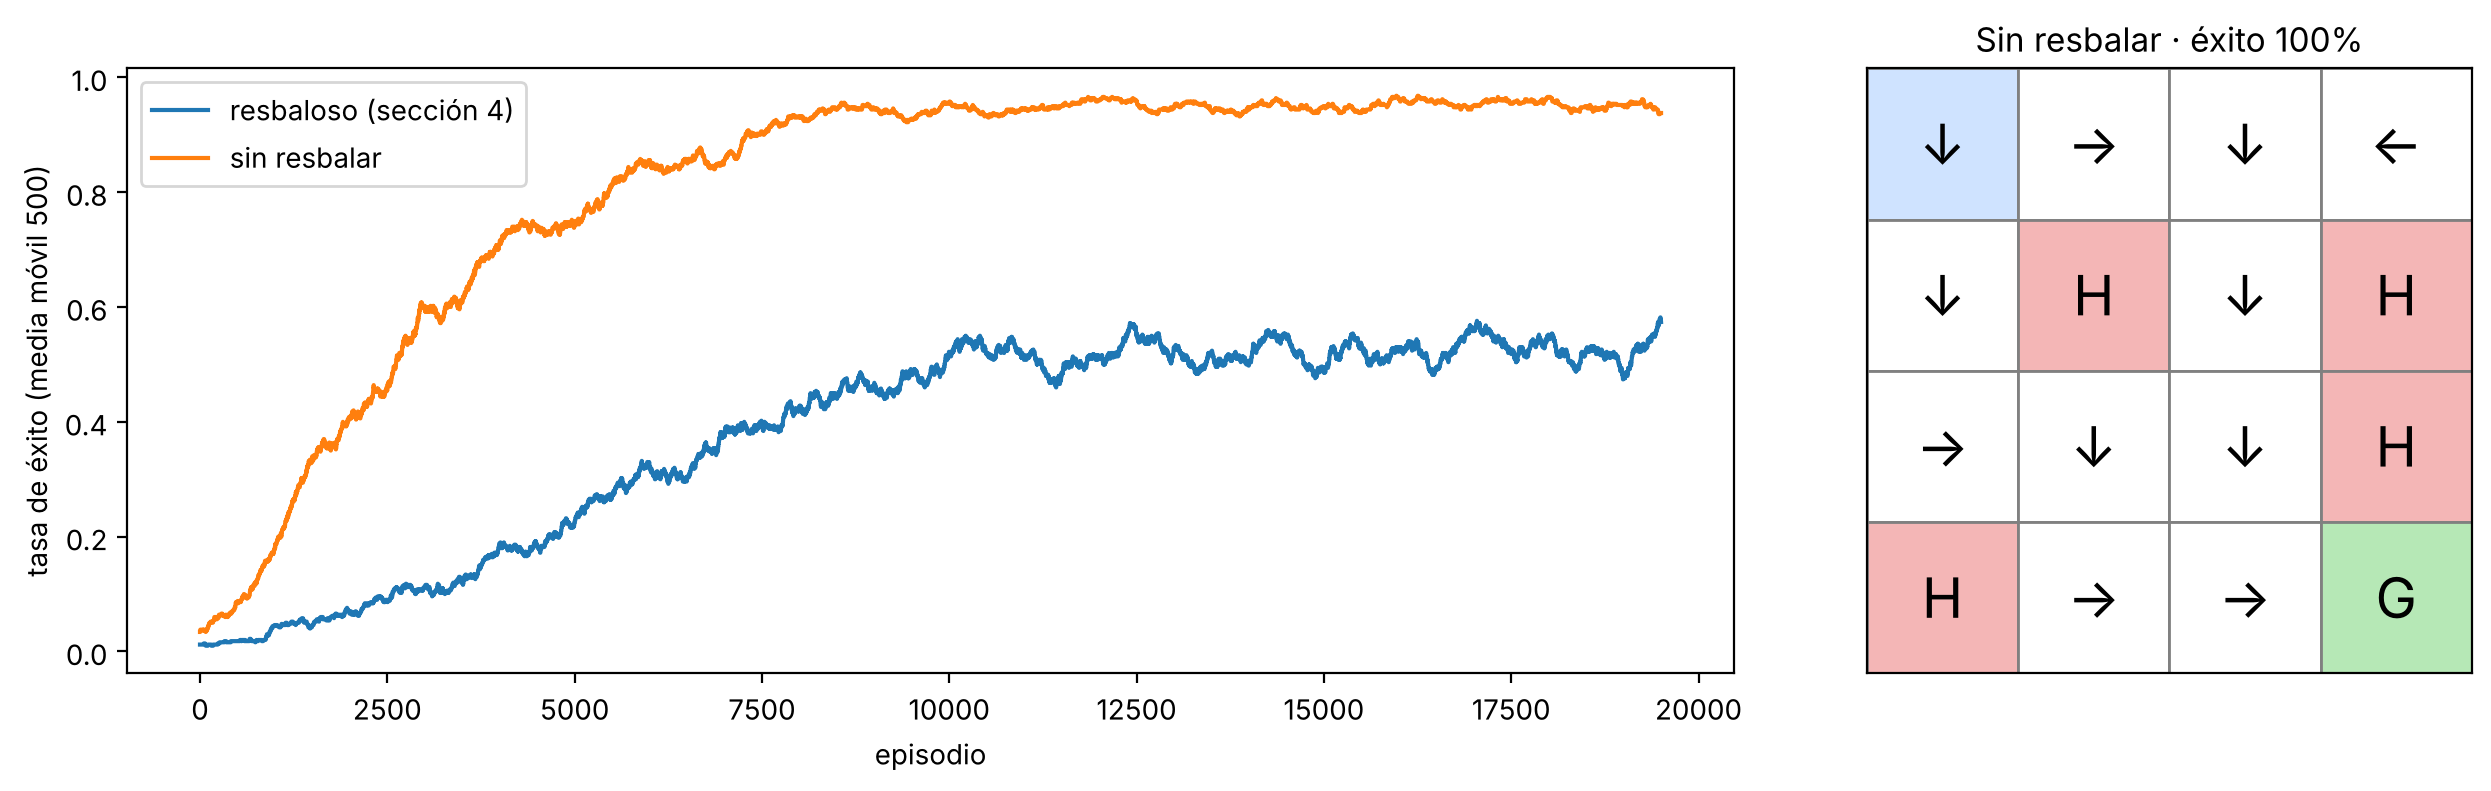

In [20]:
env_det = gym.make("FrozenLake-v1", is_slippery=False)
P_det, R_det = construir_modelo(env_det)              # solo para comparar
V = np.zeros(nS)
for _ in range(1500):
    Q_star_det = R_det + gamma * np.einsum("sap,p->sa", P_det, V)
    V = Q_star_det.max(axis=1)
pi_star_det = Q_star_det.argmax(axis=1)

Q_det, ret_det = q_learning(env_det, gamma=gamma)
pi_det = Q_det.argmax(axis=1)

def episodio_umbral(ret, umbral):
    m = media(ret)
    return int(np.argmax(m >= umbral)) + w if (m >= umbral).any() else None

filas = []
for nombre, e, ret, pi, Qs in [("resbaloso", env, ret_ql, pi_ql, Q_star), ("sin resbalar", env_det, ret_det, pi_det, Q_star_det)]:
    exito, largo, _ = resumen_politica(e, pi)
    filas.append({"entorno": nombre,
                  "primer éxito (episodio)": int(np.argmax(ret > 0)),
                  "media móvil >= 0.5 (episodio)": episodio_umbral(ret, 0.5),
                  "éxito entrenando (últimos 2000)": f"{ret[-2000:].mean():.1%}",
                  "éxito greedy": f"{exito:.1%}",
                  "pasos por episodio": round(largo, 1),
                  "V(0) aprendido": round(Q_det[0].max() if nombre == "sin resbalar" else Q_ql[0].max(), 3),
                  "V*(0)": round(Qs[0].max(), 3),
                  "error |Q-Q*|": round(np.abs((Q_det if nombre == "sin resbalar" else Q_ql) - Qs)[no_term].mean(), 3),
                  "política = π*": bool((pi == Qs.argmax(1))[no_term].all())})
display(pd.DataFrame(filas).set_index("entorno").T)

fig = plt.figure(figsize=(13, 4))
ax0 = fig.add_subplot(1, 3, (1, 2))
ax0.plot(media(ret_ql), label="resbaloso (sección 4)")
ax0.plot(media(ret_det), label="sin resbalar")
ax0.set_xlabel("episodio"); ax0.set_ylabel(f"tasa de éxito (media móvil {w})"); ax0.legend()
graficar_politica(pi_det, env_det, f"Sin resbalar · éxito {resumen_politica(env_det, pi_det)[0]:.0%}", fig.add_subplot(1, 3, 3))
plt.tight_layout(); plt.show()

**Interpretación.** Sin resbalar el problema es determinista y Q-Learning aprende mucho más rápido: el primer éxito llega en el episodio 41 (contra 67), la media móvil pasa de 0.5 en el episodio 3,113 (contra 10,334) y al final del entrenamiento acierta 95.1% (contra 53.2%).
La política greedy es óptima: llega en 6 pasos, el mínimo posible, con 100% de éxito, y $V(0)=0.951=0.99^5$ coincide con $V^\star(0)$ (la recompensa llega en el sexto paso, así que se descuenta cinco veces). El error contra $Q^\star$ es 0.009, cinco veces menor que con hielo: sin resbalones cada muestra $(s,a,r,s')$ ya es el valor esperado, así que no hay ruido que promediar y el $\alpha$ fijo deja de ser un problema.
También cambia la forma de la política. Ya no hace falta la estrategia de "empujar contra la pared" (← en la salida) para aprovechar el resbalón; el agente va directo hacia abajo y a la derecha. El 95.1% de entrenamiento no llega a 100% solo por la exploración con $\varepsilon=0.05$.

## Ejercicio (b). Castigo de $-0.01$ por paso con `gym.RewardWrapper`

El wrapper le resta 0.01 a toda recompensa, así que llegar a la meta da 0.99 y cualquier otro paso da $-0.01$. El agente se entrena en el entorno con castigo, pero la política se evalúa en el entorno original para medir el éxito real.
Como referencia, también calculo con value iteration la política óptima con castigo (restando el castigo en los estados no terminales). Agrego un castigo de $-0.05$ para ver qué pasa cuando el castigo es más fuerte.

éxito   hoyo truncado  pasos por episodio  \
castigo política                                                
0.00    Q-Learning  74.2%  15.6%    10.1%                44.0   
        DP          74.2%  15.6%    10.1%                44.0   
0.01    Q-Learning  74.6%  19.1%     6.3%                41.0   
        DP          73.5%  20.7%     5.9%                40.6   
0.05    Q-Learning   2.5%  97.5%     0.0%                 4.7   
        DP           5.4%  94.6%     0.0%                 5.0   

                    acciones distintas a π*  
castigo política                             
0.00    Q-Learning                        0  
        DP                                0  
0.01    Q-Learning                        2  
        DP                                1  
0.05    Q-Learning                       11  
        DP                                9

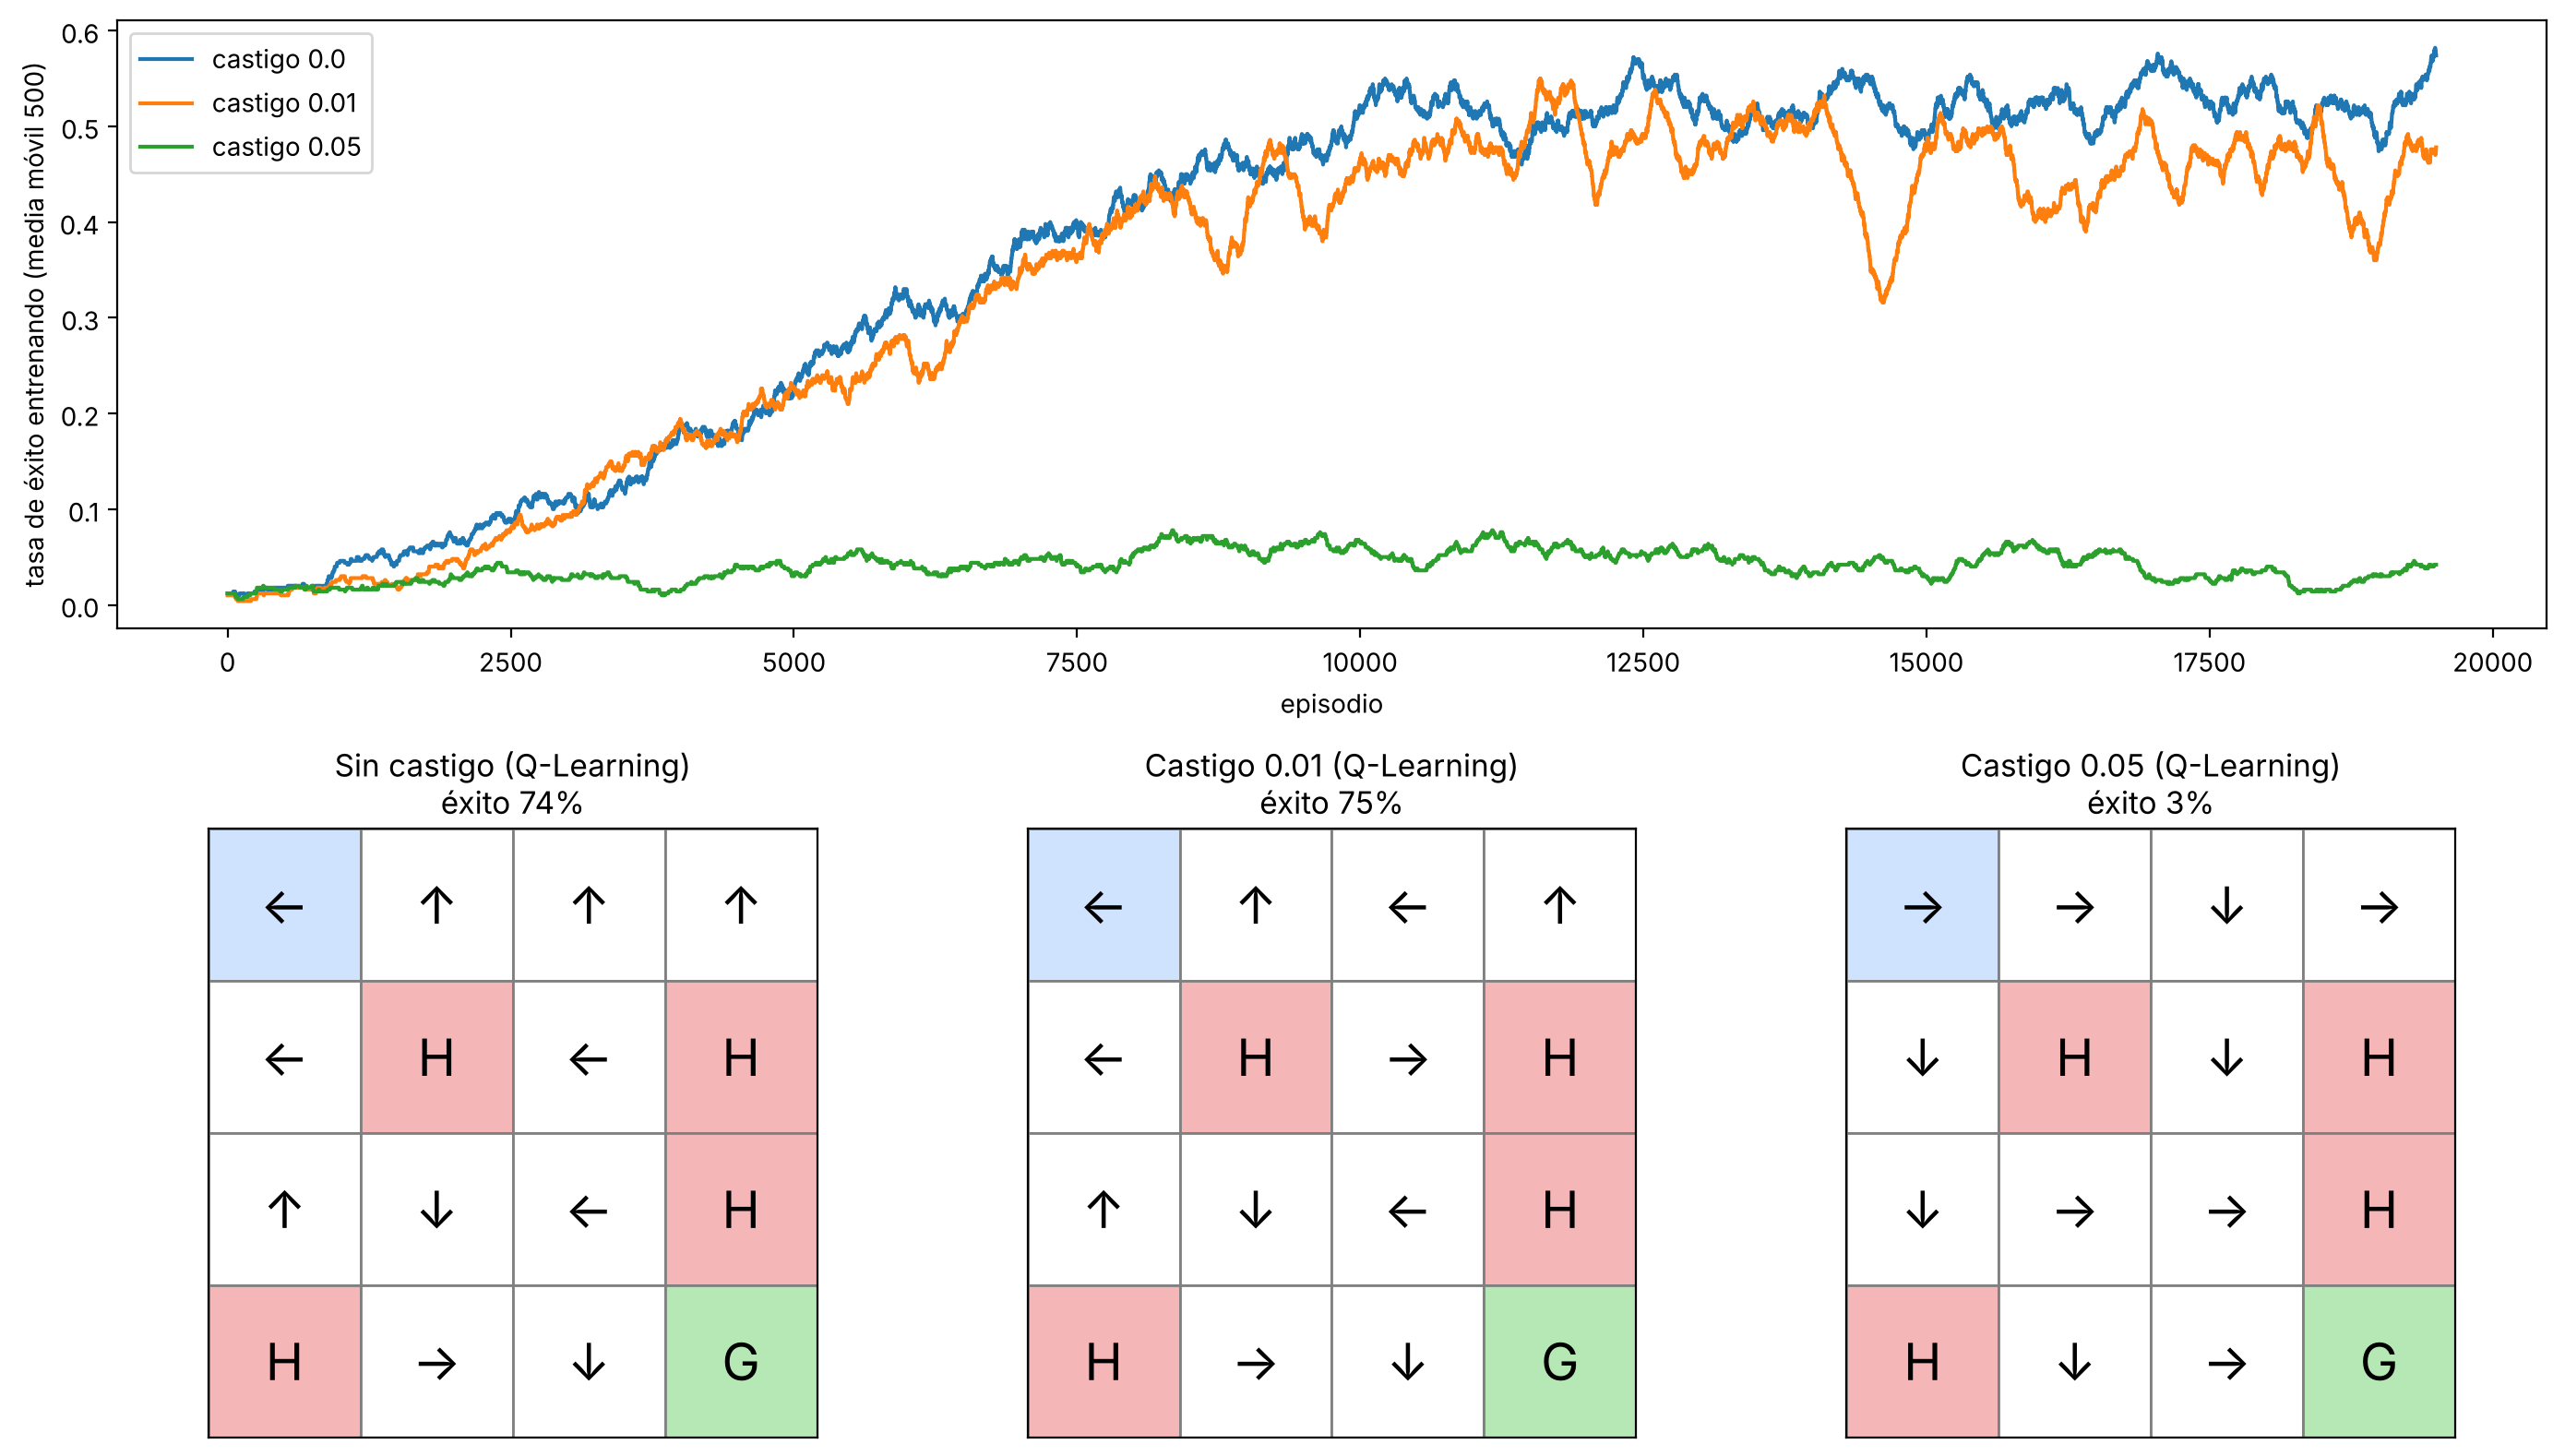

In [21]:
class CastigoPorPaso(gym.RewardWrapper):
    def __init__(self, env, castigo=0.01):
        super().__init__(env)
        self.castigo = castigo

    def reward(self, r):
        return r - self.castigo

terminales = estados_terminales(env)
def pi_dp_castigo(castigo):
    R_c = R.copy()
    R_c[no_term] -= castigo                          # los estados terminales siguen valiendo 0
    V = np.zeros(nS)
    for _ in range(1500):
        Q_c = R_c + gamma * np.einsum("sap,p->sa", P, V)
        V = Q_c.max(axis=1)
    return Q_c.argmax(axis=1)

resultados_b, politicas_b, curvas_b = [], {}, {}
for castigo in [0.0, 0.01, 0.05]:
    if castigo == 0.0:
        Q_c, ret_c = Q_ql, ret_ql                    # el de la sección 4
    else:
        Q_c, ret_c = q_learning(CastigoPorPaso(gym.make("FrozenLake-v1", is_slippery=True), castigo), gamma=gamma)
    curvas_b[castigo] = (ret_c > 0).astype(float)    # la meta es la única recompensa positiva
    for origen, pi in [("Q-Learning", Q_c.argmax(1)), ("DP", pi_dp_castigo(castigo))]:
        exito, largo, trunc = resumen_politica(env, pi)
        politicas_b[(castigo, origen)] = pi
        resultados_b.append({"castigo": castigo, "política": origen, "éxito": f"{exito:.1%}",
                             "hoyo": f"{1 - exito - trunc:.1%}", "truncado": f"{trunc:.1%}",
                             "pasos por episodio": round(largo, 1),
                             "acciones distintas a π*": int((pi != pi_star)[no_term].sum())})
display(pd.DataFrame(resultados_b).set_index(["castigo", "política"]))

fig = plt.figure(figsize=(14, 8))
ax0 = fig.add_subplot(2, 3, (1, 3))
for castigo, c in curvas_b.items():
    ax0.plot(media(c), label=f"castigo {castigo}")
ax0.set_xlabel("episodio"); ax0.set_ylabel(f"tasa de éxito entrenando (media móvil {w})"); ax0.legend()
for k, (castigo, titulo) in enumerate([(0.0, "Sin castigo (Q-Learning)"), (0.01, "Castigo 0.01 (Q-Learning)"), (0.05, "Castigo 0.05 (Q-Learning)")]):
    pi = politicas_b[(castigo, "Q-Learning")]
    graficar_politica(pi, env, f"{titulo}\néxito {resumen_politica(env, pi)[0]:.0%}", fig.add_subplot(2, 3, 4 + k))
plt.tight_layout(); plt.show()

**Interpretación.** Con castigo de 0.01 la política sí cambia, pero poco. Q-Learning cambia 2 flechas respecto a $\pi^\star$ (celdas 2 y 6) y la de DP con castigo cambia 1 (celda 2). El éxito queda prácticamente igual (74.6% con Q-Learning y 73.5% con DP, contra 74.2%), los episodios se acortan de 44.0 a unos 41 pasos y los truncados bajan de 10.1% a cerca de 6%, a cambio de caer un poco más en hoyos (19% a 21% contra 15.6%).
La razón es que sin castigo y con $\gamma=0.99$ dar vueltas casi no cuesta, así que $\pi^\star$ es muy paciente y prefiere caminos largos y seguros. Con el castigo, un camino de 40 pasos cuesta $\sum_{k<40}0.01\cdot0.99^k\approx0.33$ en valor descontado, y al agente le conviene arriesgar un poco más para llegar antes. Como la meta vale 0.99, el castigo no alcanza para cambiar la estrategia general.
Con castigo de 0.05 cambia todo: el mismo camino cuesta unos 1.65, más que lo que vale la meta, y lo óptimo es tirarse a un hoyo lo antes posible (DP: 94.6% hoyo en 5 pasos; Q-Learning aprendió lo mismo y solo tiene 2.5% de éxito). El agente no está "mal": maximiza la recompensa que le dimos, que ya no equivale a llegar a la meta. Para trading la lección es que cambiar la recompensa (castigos por operar, por riesgo, etc.) cambia el problema que se resuelve, así que hay que revisar qué política es óptima con esa recompensa antes de entrenar.
La curva con castigo 0.01 es más inestable después del episodio 13,000 (baja hasta 0.32 cerca del 14,500): con el castigo, arriesgar y esperar tienen valores muy parecidos en algunas celdas y el ruido del $\alpha$ fijo hace que la acción elegida cambie.

## Ejercicio (c). Q-Learning tabular en `TradingEnv`

**Diseño, sin look-ahead:**
- Divido la serie de 500 barras en entrenamiento (barras 0 a 349) y prueba (350 a 499). El entorno de prueba recibe también las 30 barras anteriores, solo para armar la primera observación.
- La observación en $t$ ya trae los rendimientos hasta $t-1$. Tomo el último, `obs[-2]` $=r_{t-1}$, y lo discretizo con cuantiles calculados **solo con los rendimientos de entrenamiento**.
- Estado discreto = (bin del último rendimiento, posición $\in\{-1,0,+1\}$), es decir, `n_bins x 3` estados y 3 acciones.
- Entreno 300 episodios (cada episodio recorre todo el periodo de entrenamiento) con $\alpha=0.1$, $\gamma=0.99$ y $\varepsilon$ de 1 a 0.05 (factor 0.985 por episodio). Después evalúo la política greedy en entrenamiento y en prueba.
- Repito con 2, 3, 5, 10, 20 y 50 bins para ver dónde se rompe.

In [22]:
corte, W = 350, env_tr.window
df_train = df.iloc[:corte].reset_index(drop=True)
df_test = df.iloc[corte - W:].reset_index(drop=True)     # las 30 barras previas solo alimentan la 1a observación
env_train, env_test = TradingEnv(df_train), TradingEnv(df_test)

def bordes_bins(n_bins):
    # Cuantiles del rendimiento usando SOLO datos de entrenamiento (sin el 0 inicial del fillna).
    return np.quantile(df_train["ret"].iloc[1:], np.linspace(0, 1, n_bins + 1)[1:-1])

def discretizar(obs, bordes):
    # obs[-2] = último rendimiento observado (t-1), obs[-1] = posición actual en {-1, 0, 1}
    return int(np.digitize(obs[-2], bordes)) * 3 + int(obs[-1]) + 1

def q_learning_trading(env, bordes, episodios=300, alpha=0.1, gamma=0.99,
                       eps=1.0, eps_min=0.05, decay=0.985, semilla=SEED):
    n_est = (len(bordes) + 1) * 3
    rng = np.random.default_rng(semilla)
    Q, N = np.zeros((n_est, 3)), np.zeros((n_est, 3))
    equity_ep = []
    env.reset(seed=semilla)
    for ep in range(episodios):
        obs, _ = env.reset()
        s = discretizar(obs, bordes)
        terminado = truncado = False
        while not (terminado or truncado):
            a = int(rng.integers(3)) if rng.random() < eps else int(Q[s].argmax())
            obs, r, terminado, truncado, info = env.step(a)
            s2 = discretizar(obs, bordes)
            futuro = 0.0 if terminado else Q[s2].max()          # fin de datos = truncated -> sí bootstrap
            Q[s, a] += alpha * (r + gamma * futuro - Q[s, a])
            N[s, a] += 1
            s = s2
        equity_ep.append(info["equity"] - env.init_cash)
        eps = max(eps_min, eps * decay)
    return Q, N, np.array(equity_ep)

def evaluar_greedy(env, Q, bordes):
    obs, _ = env.reset(seed=SEED)
    terminado = truncado = False
    posiciones = []
    while not (terminado or truncado):
        a = int(Q[discretizar(obs, bordes)].argmax())
        posiciones.append(a - 1)
        obs, r, terminado, truncado, info = env.step(a)
    return info["equity"] - env.init_cash, np.array(posiciones)

# referencia: buy-and-hold en cada periodo
bh = {}
for nombre, e in [("train", env_train), ("test", env_test)]:
    eq, _, _ = correr(e, lambda obs: 2)
    bh[nombre] = eq - e.init_cash
print(f"Buy-and-hold:  entrenamiento {bh['train']:+.2f} USD   prueba {bh['test']:+.2f} USD   "
      f"(barras: {len(df_train) - 1 - W} y {len(df_test) - 1 - W})")

filas, modelos = [], {}
rets_obs = df_train["ret"].iloc[W - 1:-2].values         # los r_{t-1} que ve el agente en entrenamiento
for n_bins in [2, 3, 5, 10, 20, 50]:
    b = bordes_bins(n_bins)
    Q, N, eq_ep = q_learning_trading(env_train, b)
    pnl_tr, pos_tr = evaluar_greedy(env_train, Q, b)
    pnl_te, pos_te = evaluar_greedy(env_test, Q, b)
    barras_bin = np.bincount(np.digitize(rets_obs, b), minlength=n_bins)
    modelos[n_bins] = (Q, N, eq_ep)
    filas.append({"bins": n_bins, "estados": 3 * n_bins,
                  "barras distintas por bin": round(barras_bin.mean(), 1),
                  "P&L train (USD)": round(pnl_tr, 2), "P&L test (USD)": round(pnl_te, 2),
                  "operaciones test": int(np.abs(np.diff(np.r_[0, pos_te])).sum()),
                  "% largo test": f"{(pos_te == 1).mean():.0%}", "% corto test": f"{(pos_te == -1).mean():.0%}",
                  "% fuera test": f"{(pos_te == 0).mean():.0%}"})
tabla_c = pd.DataFrame(filas).set_index("bins")
display(tabla_c)

Buy-and-hold:  entrenamiento +1.30 USD   prueba +3.23 USD   (barras: 319 y 149)


,estados,barras distintas por bin,P&L train (USD),P&L test (USD),operaciones test,% largo test,% corto test,% fuera test
bins,,,,,,,,
2,6,159.5,0.00,0.00,0,0%,0%,100%
3,9,106.3,0.00,0.00,0,0%,0%,100%
5,15,63.8,0.00,0.00,0,0%,0%,100%
10,30,31.9,0.00,0.00,0,0%,0%,100%
20,60,16.0,38.84,-0.17,95,30%,26%,44%
50,150,6.4,78.58,-8.07,126,47%,46%,7%


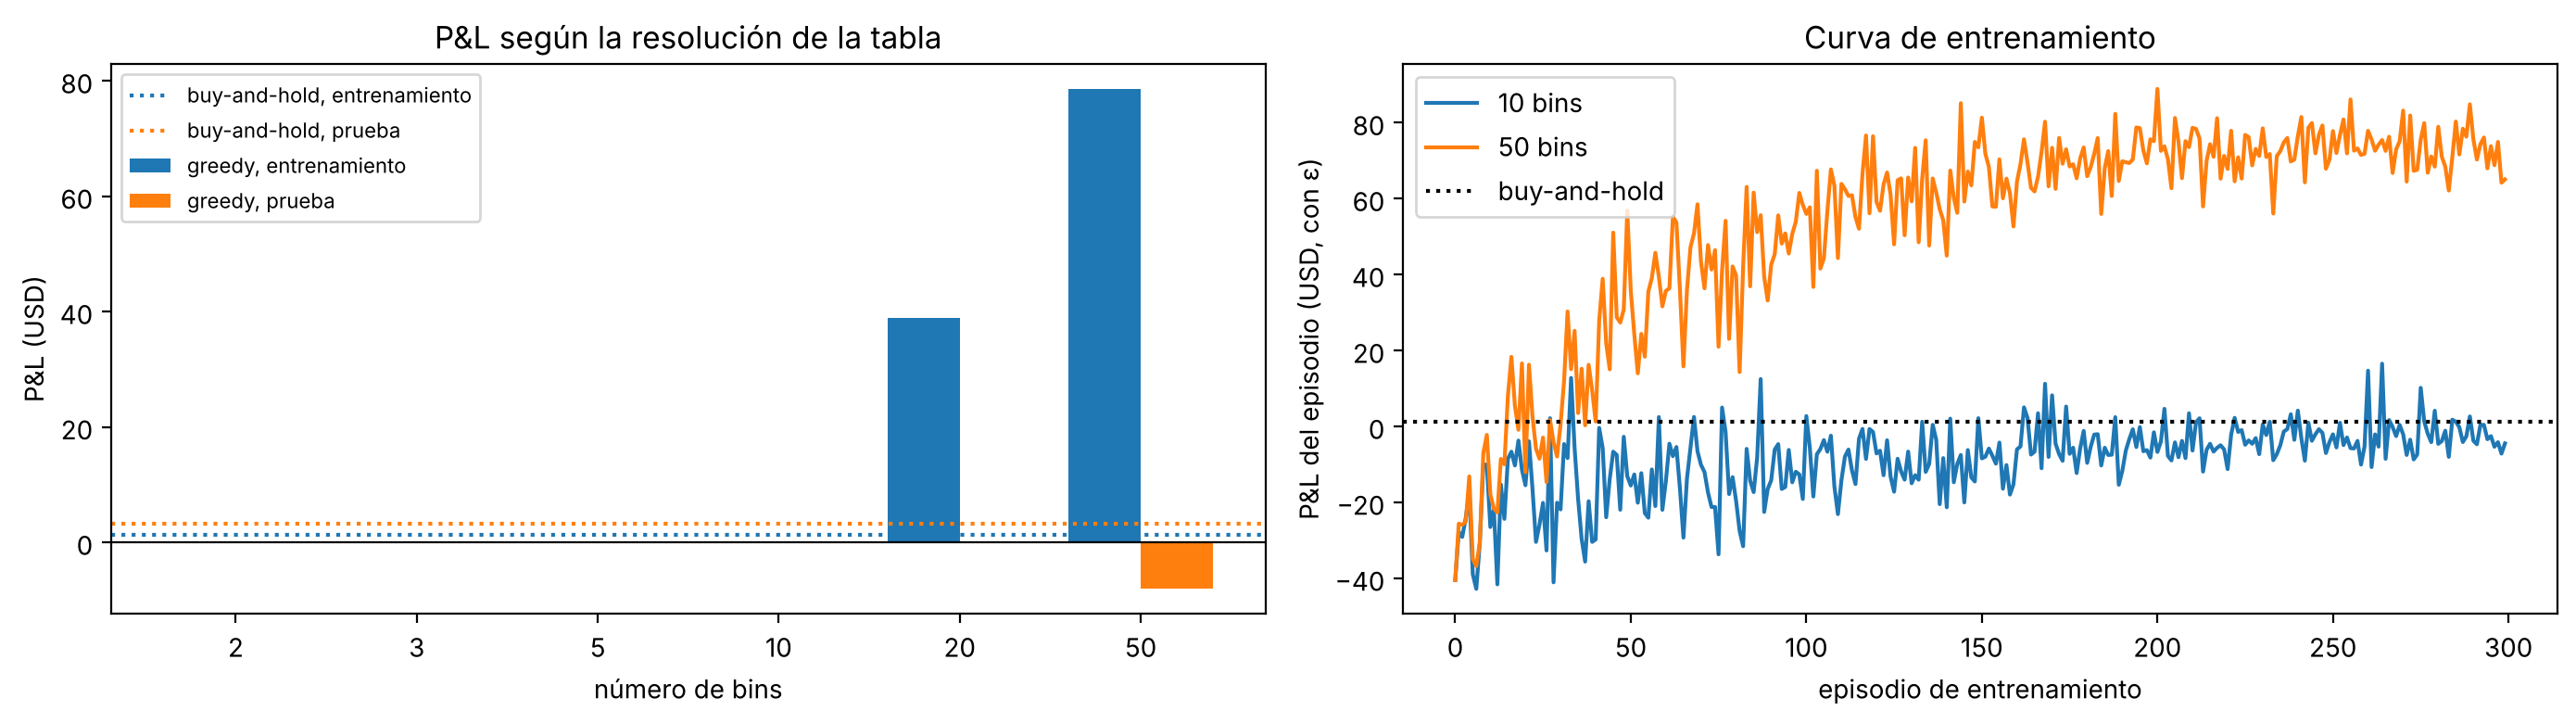

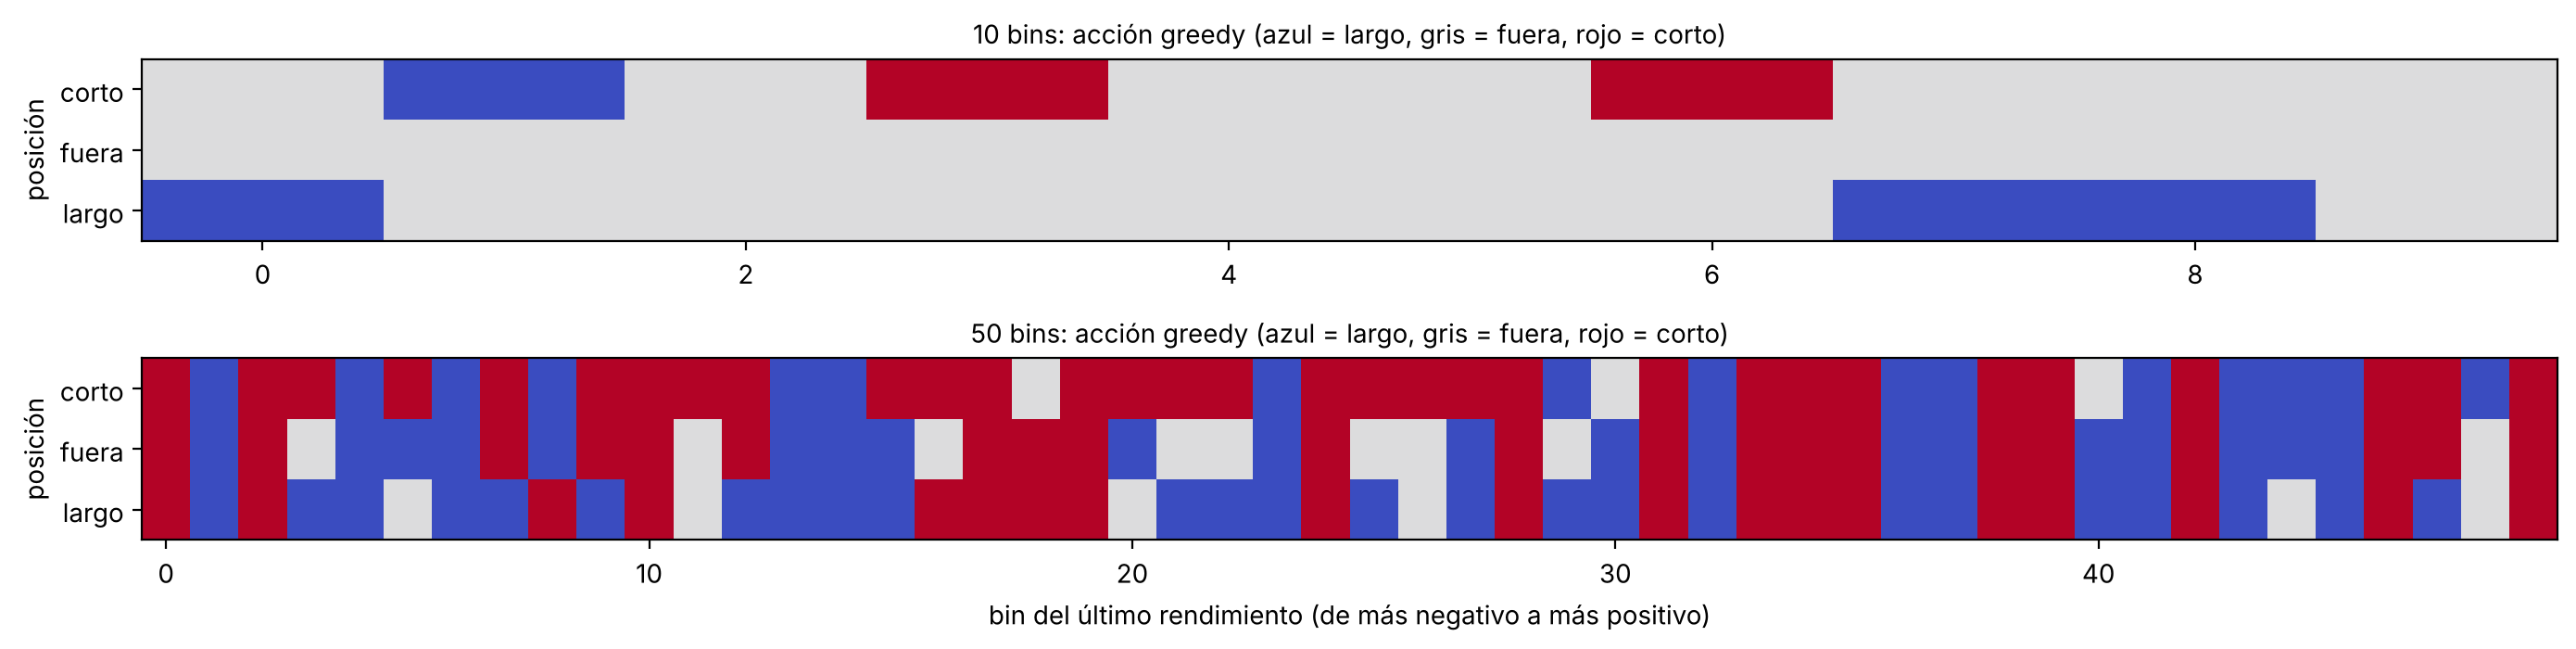

Q(s,a) con 10 bins, estado 'fuera', primeros 5 bins (escala 1e-5):
[[0.14 0.37 0.37]
 [0.17 0.36 0.16]
 [0.06 0.37 0.02]
 [0.23 0.36 0.01]
 [0.34 0.36 0.29]]


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(tabla_c))
ax[0].bar(x - 0.2, tabla_c["P&L train (USD)"], 0.4, label="greedy, entrenamiento")
ax[0].bar(x + 0.2, tabla_c["P&L test (USD)"], 0.4, label="greedy, prueba")
ax[0].axhline(bh["train"], color="C0", ls=":", label="buy-and-hold, entrenamiento")
ax[0].axhline(bh["test"], color="C1", ls=":", label="buy-and-hold, prueba")
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_xticks(x, tabla_c.index); ax[0].set_xlabel("número de bins"); ax[0].set_ylabel("P&L (USD)")
ax[0].set_title("P&L según la resolución de la tabla"); ax[0].legend(fontsize=8)

for n_bins in [10, 50]:
    ax[1].plot(modelos[n_bins][2], label=f"{n_bins} bins")
ax[1].axhline(bh["train"], color="k", ls=":", label="buy-and-hold")
ax[1].set_xlabel("episodio de entrenamiento"); ax[1].set_ylabel("P&L del episodio (USD, con ε)")
ax[1].set_title("Curva de entrenamiento"); ax[1].legend()
plt.tight_layout(); plt.show()

# política greedy aprendida: fila = posición actual, columna = bin del último rendimiento
fig, ax = plt.subplots(2, 1, figsize=(14, 3.6))
for k, n_bins in enumerate([10, 50]):
    Q = modelos[n_bins][0]
    mapa = Q.argmax(1).reshape(n_bins, 3).T - 1           # -1 corto, 0 fuera, +1 largo
    ax[k].imshow(mapa, cmap="coolwarm_r", vmin=-1, vmax=1, aspect="auto")
    ax[k].set_yticks([0, 1, 2], ["corto", "fuera", "largo"]); ax[k].set_ylabel("posición")
    ax[k].set_title(f"{n_bins} bins: acción greedy (azul = largo, gris = fuera, rojo = corto)", fontsize=10)
ax[1].set_xlabel("bin del último rendimiento (de más negativo a más positivo)")
plt.tight_layout(); plt.show()

Q10 = modelos[10][0]
print("Q(s,a) con 10 bins, estado 'fuera', primeros 5 bins (escala 1e-5):")
print((Q10.reshape(10, 3, 3)[:5, 1, :] * 1e5).round(2))

**Interpretación: dónde se rompe.**

1. **Con 10 bins o menos no aprende nada útil.** La política greedy se queda fuera del mercado todo el tiempo (P&L de 0 en entrenamiento y en prueba), mientras que buy-and-hold habría ganado 1.30 y 3.23 USD. Es un problema de escala: el drift es 0.03% por barra (unos 3 centavos con un precio de 100), el ruido es 1% (1 dólar) y entrar cuesta 0.1% (10 centavos). Con unas 32 barras por bin, el error estándar del promedio del siguiente movimiento dentro de un bin es de unos $1/\sqrt{32}\approx 0.18$ USD, más grande que cualquier señal real. Los valores Q son del orden de $10^{-6}$ y la diferencia entre acciones es menor que el ruido de una sola barra, así que gana "fuera", que no paga comisión. Durante el entrenamiento el P&L es negativo por las comisiones de las acciones al azar.
2. **Con 20 bins o más aprende el ruido.** Con 50 bins quedan unas 6 barras distintas por bin y la tabla puede memorizar en qué bins el siguiente movimiento fue positivo dentro de la muestra. La curva de entrenamiento sube hasta 70-80 USD y la política greedy gana 78.58 USD en entrenamiento, 60 veces lo de buy-and-hold, pero en prueba pierde 8.07 USD con 126 operaciones. El mapa de la política lo confirma: con 50 bins la acción salta de largo a corto entre bins vecinos sin ningún patrón. La serie es una caminata aleatoria, así que no existe una relación real entre el último rendimiento y el siguiente que lo explique.
3. **No hay un punto intermedio.** Con pocos bins la tabla no tiene resolución y con muchos no tiene datos por celda. Además esto es con una sola feature: si se agrega un segundo rendimiento rezagado con 50 bins quedan 7,500 estados para 319 barras, menos de una barra por estado. Repetir los 300 episodios no ayuda, porque siempre son las mismas 319 transiciones y más épocas solo memorizan mejor. Cada bin aprende por separado, aunque bins vecinos deberían comportarse parecido.

Este es el problema que motiva la S19: se necesita una $Q_\theta(s,a)$ que reciba el rendimiento como número continuo, comparta parámetros entre estados parecidos y se regularice para no memorizar. Una DQN no va a crear una señal que esta serie no tiene, pero sí ataca el dilema entre resolución y datos que rompe la tabla.

*Nota sobre el mapa de 10 bins:* aparecen algunas acciones de largo o corto en las filas donde ya se tiene posición, pero esas celdas nunca se alcanzan con la política greedy, porque desde "fuera" nunca entra.

## Conclusión

Q-Learning tabular funciona bien cuando el problema es chico y el estado es suficiente (FrozenLake: 16 estados, misma política que programación dinámica). Los experimentos también muestran sus límites: con $\alpha$ fijo no converge exactamente (pregunta 2), el `max` sobreestima cuando hay ruido (pregunta 4), confundir `terminated` con `truncated` corrompe los valores en los dos sentidos (sección 5 y pregunta 5) y un castigo por paso cambia el objetivo, no solo la velocidad (ejercicio b).
En trading el problema se junta: la señal es débil, el ruido es grande y la tabla tiene que escoger entre no tener resolución o no tener datos (ejercicio c). Lo que falta es una función $Q_\theta(s,a)$ que generalice entre estados parecidos, que es el tema de la S19 (DQN).